In [ ]:
from grid_adventure.grid import step as grid_step
from grid_adventure.step import Action
from grid_adventure.entities import AgentEntity
from public_levels.intro import build_level_hazard_detour

def changed(a, b):
    return str(a.grid) != str(b.grid)

def agent_health(state):
    for x in range(state.width):
        for y in range(state.height):
            for e in state.objects_at((x, y)):
                if isinstance(e, AgentEntity):
                    return e.health

s0 = build_level_hazard_detour()
print("start health:", agent_health(s0))

# WAIT: nothing but the turn should change
s1 = grid_step(s0, Action.WAIT)
print("WAIT -> grid string changed:", changed(s0, s1))

# Three RIGHT moves walk the agent onto the lava at (4, 4)
s = s0
for a in [Action.RIGHT, Action.RIGHT, Action.RIGHT]:
    prev, s = s, grid_step(s, a)
    print(a.name, "| changed:", changed(prev, s),
          "| health:", agent_health(s), "| score:", s.score)
s_next = grid_step(s, Action.WAIT)
print("string changed:", changed(s, s_next),
      "| health:", agent_health(s_next).current_health,
      "| lose:", s_next.lose)

In [ ]:
from public_levels.intro import build_level_key_door

def agent_entity(state):
    for x in range(state.width):
        for y in range(state.height):
            for e in state.objects_at((x, y)):
                if isinstance(e, AgentEntity):
                    return e

k = build_level_key_door()          # agent at (1, 4), key at (2, 3)
for a in [Action.UP, Action.RIGHT, Action.PICK_UP]:
    k = grid_step(k, a)

print(agent_entity(k))

In [ ]:
from public_levels.intro import build_level_power_shield

s = build_level_power_shield()
# Up to the shield, then pick it up
for a in [Action.UP, Action.UP, Action.UP, Action.RIGHT, Action.PICK_UP]:
    s = grid_step(s, a)
print("after pickup:", agent_entity(s))

# Back down and across, onto the lava
for a in [Action.DOWN, Action.DOWN, Action.DOWN, Action.RIGHT, Action.RIGHT, Action.RIGHT]:
    s = grid_step(s, a)
print("on lava:", agent_entity(s))

In [ ]:
import heapq
import time
from public_levels.intro import build_level_basic_movement, build_level_optional_coin
from public_levels.catalog import PUBLIC_LEVEL_MAX_REWARDS

def plan(start):
    counter = 0
    heap = [(0, counter, start, [])]  # (priority, counter, state, path)
    best = {str(start.grid): 0}  # best score for each grid string
    while heap:
        _, _, state, path = heapq.heappop(heap)
        if  best[str(state.grid)] > state.score:
            continue  # Skip if we have already found a better score for this grid
        if state.win:
            return path
        for action in Action:
            next_state = grid_step(state, action)
            if next_state.lose:
                continue
            else:
                next_score = next_state.score
                next_grid_str = str(next_state.grid)
                if next_grid_str not in best or next_score > best[next_grid_str]:
                    best[next_grid_str] = next_score
                    counter += 1
                    heapq.heappush(heap, (-next_score, counter, next_state, path + [action]))
    return [Action.WAIT]  # No path found, return a default action

def run_plan(builder):
    s = builder()
    for a in plan(s):
        s = grid_step(s, a)
    return s.score, s.win

t = time.time()
print(run_plan(build_level_optional_coin), PUBLIC_LEVEL_MAX_REWARDS["A2 Optional Coin Path"])  # should return (0, True)
print(f"Time taken: {time.time() - t:.2f} seconds")


In [ ]:
 # Input states for Agent step function
import heapq

from grid_adventure.grid import GridState
from grid_adventure.env import ImageObservation
from grid_adventure.constants import STEP_COST
from grid_adventure.entities import (
    AgentEntity,
    BoxEntity,
    CoinEntity,
    ExitEntity,
    GemEntity,
    KeyEntity,
    LavaEntity,
    LockedDoorEntity,
    PhasingPowerUpEntity,
    ShieldPowerUpEntity,
    SpeedPowerUpEntity,
    UnlockedDoorEntity,
    WallEntity,
)
from grid_adventure.movements import MOVEMENTS
from grid_adventure.objectives import OBJECTIVES
from grid_adventure.rendering import DEFAULT_ASSET_ROOT
from grid_universe.grid.entity import BaseEntity

# State steppers
from grid_adventure.step import Action
from grid_adventure.grid import step as grid_step

# Utility helpers
from collections import deque
from pathlib import Path
import numpy as np
from PIL import Image

PICKABLE = (CoinEntity, GemEntity, KeyEntity,
            SpeedPowerUpEntity, ShieldPowerUpEntity, PhasingPowerUpEntity)

OPPOSITE = {Action.UP: Action.DOWN, Action.DOWN: Action.UP,
            Action.LEFT: Action.RIGHT, Action.RIGHT: Action.LEFT}

class Agent:
    """Grid Adventure: Variant 1 agent template.

    This class is the single public interface that Coursemology will import and
    interact with when evaluating your submission. You should extend the
    internals (add helper classes / functions in other files if you wish) but
    MUST preserve:

    1. The class name: Agent
    2. The public method: step(self, state: GridState | ImageObservation) -> Action

    High-level lifecycle per environment tick:
        state  --->  step(...)  --->  Action

    The "state" object type depends on the task:
    - Task 1: A fully structured GridState instance.
    - Task 2: An ImageObservation dictionary whose primary observation is an RGBA image
      plus limited structured metadata in the 'info' sub-dict. In this case you
      typically perform perception to build (or approximate) an internal
      structured representation before planning.
    - Task 3: Input state could be either a GridState instance 
      or an ImageObservation dictionary

    Constraints:
    - Keep per-step latency small (single CPU, 1.5 GB RAM). Avoid O(W*H) scans of
      the full grid every step.
    - Determinism helps reproducibility; seed your own RNG if you add any
      random components.

    You may add __init__ parameters (with defaults) if needed for your own
    development, but the grader will instantiate Agent() with no arguments.
    """

    def __init__(self):
        """Initialize your agent.

        Put all one-time setup here (e.g., hardcoded ML model weights, 
        precomputing heuristic tables). Keep it fast and memory-light 
        to respect platform limits.
        """
        self.actions = None  # store previous actions or state

    def agent_pos(self, state: GridState):
        for y in range(state.height):
            for x in range(state.width):
                for e in state.objects_at((x, y)):
                    if isinstance(e, AgentEntity):
                        return (x, y)
        raise ValueError("no agent found in state")

    def item_name(self, i) -> str:
        appearance = getattr(i, "appearance", None)
        return appearance.name if appearance is not None else "unknown"

    def blocked(self, state: GridState, cell):
        """Check if a cell is blocked for the agent."""
        if not (0 <= cell[0] < state.width and 0 <= cell[1] < state.height):
            return True
        for e in state.objects_at(cell):
            if isinstance(e, (WallEntity, LockedDoorEntity)):
                return True
        return False

    def count_of(self, state: GridState, kind) -> int:
        n = 0
        for y in range(state.height):
            for x in range(state.width):
                for e in state.objects_at((x, y)):
                    if isinstance(e, kind):
                        n += 1
        return n
    
    def find_all(self, state: GridState, kind) -> list:
        out = []
        for y in range(state.height):
            for x in range(state.width):
                for e in state.objects_at((x, y)):
                    if isinstance(e, kind):
                        out.append((x, y))
        return out 
    
    def find_exit(self, state: GridState):
        for y in range(state.height):
            for x in range(state.width):
                for e in state.objects_at((x, y)):
                    if isinstance(e, ExitEntity):
                        return (x, y)
        raise ValueError("no exit found in state")

    def h(self, state: GridState, exit_pos, n_coins, n_boots, ghosts, K, exit_tab, gems, gem_tabs):
        INF = float("inf")
        pos = self.agent_pos(state)
        agent = [e for e in state.objects_at(pos) if isinstance(e, AgentEntity)][0]
        no_row = [INF] * (K + 1)

        # how many more wall cells the agent could still pass through
        turns_left = max([self.effect_turns(s) for s in agent.status_list
                        if getattr(s, "phasing", None) is not None] + [0])
        ghosts_left = sum(1 for g in ghosts
                        if any(isinstance(e, PhasingPowerUpEntity) for e in state.objects_at(g)))
        B = min(K, (turns_left + 5 * ghosts_left) * (2 if n_boots else 1))
        b_here = min(K, B + (1 if pos in self.walls else 0))   # standing inside a wall counts once

        d = exit_tab.get(pos, no_row)[b_here]
        for g in gems:
            if any(isinstance(e, GemEntity) for e in state.objects_at(g)):     # gem still there
                d = max(d, gem_tabs[g].get(pos, no_row)[b_here] + exit_tab.get(g, no_row)[B])
        if d == INF:
            return INF                     # exit or a gem is unreachable now: dead state
        m = max(0, d - 5 * n_boots)
        return max(m, 3 * m - 2 * n_coins)

    def budget_table(self, state: GridState, target, K: int) -> dict:
        """For each cell: fewest steps to target using at most b wall cells, for b = 0..K."""
        INF = float("inf")
        start = (target, 0)
        dist = {start: 0}
        queue = deque([start])
        while queue:
            (x, y), used = queue.popleft()
            for n in ((x, y - 1), (x, y + 1), (x - 1, y), (x + 1, y)):
                if not (0 <= n[0] < state.width and 0 <= n[1] < state.height):
                    continue
                nu = used + (1 if n in self.walls else 0)
                if nu > K or (n, nu) in dist:
                    continue
                dist[(n, nu)] = dist[((x, y), used)] + 1
                queue.append((n, nu))
        table = {}
        for (cell, used), d in dist.items():
            row = table.setdefault(cell, [INF] * (K + 1))
            for b in range(used, K + 1):
                row[b] = min(row[b], d)
        return table
    
    def legal_actions(self, state: GridState, last_action = None) -> list[Action]:
        pos = self.agent_pos(state)
        x, y = pos
        here = state.objects_at(pos)
        agent = [e for e in here if isinstance(e, AgentEntity)][0]
        phasing = any(getattr(s, "phasing", None) is not None for s in agent.status_list)
        neighbours = ((Action.UP, (x, y - 1)), (Action.DOWN, (x, y + 1)),
                    (Action.LEFT, (x - 1, y)), (Action.RIGHT, (x + 1, y)))
        speed = any(getattr(s, "speed", None) is not None for s in agent.status_list)
        shielded = any(self.effect_uses(s) > 0 for s in agent.status_list)
        hp = agent.health.current_health
        undo = None if (self.has_boxes or speed or last_action is None) else OPPOSITE.get(last_action)

        actions = []
        for act, cell in neighbours:
            if act == undo:
                continue                                   # stepping straight back is never better
            if not phasing and self.blocked(state, cell):
                continue
            if (not phasing and not shielded and hp <= 2
                    and any(isinstance(e, LavaEntity) for e in state.objects_at(cell))):
                continue                                   # this lava step would kill us
            actions.append(act)

        if any(isinstance(e, PICKABLE) for e in here):        # only when there is something to pick up
            actions.append(Action.PICK_UP)

        has_key = any(self.item_name(i) == "key" for i in agent.inventory_list)
        door_next_to_me = any(
            0 <= c[0] < state.width and 0 <= c[1] < state.height
            and any(isinstance(e, LockedDoorEntity) for e in state.objects_at(c))
            for _, c in neighbours
        )
        if has_key and door_next_to_me:
            actions.append(Action.USE_KEY)
        return actions

    def effect_uses(self, s) -> int:
        ul = getattr(s, "usage_limit", None)
        return ul.amount if ul is not None else -1
    
    def effect_turns(self, s) -> int:
        tl = getattr(s, "time_limit", None)
        return tl.amount if tl is not None else -1

    def state_key(self, state: GridState) -> tuple:
        """Return a unique string key for the given state.

        This is used to track visited states in the search algorithm.
        """
        key = []
        for y in range(state.height):
            for x in range(state.width):
                for e in state.objects_at((x, y)):
                    if isinstance(e, (CoinEntity, WallEntity, LavaEntity, ExitEntity)):
                        continue
                    if isinstance(e, AgentEntity):
                        items = tuple(sorted(
                            self.item_name(i) for i in e.inventory_list if self.item_name(i) != "coin"
                        ))
                        status = tuple(sorted(
                            (self.item_name(s),
                            self.effect_turns(s),
                            self.effect_uses(s))
                            for s in e.status_list
                        ))
                        key.append((x, y, "agent", e.health.current_health, items, status))
                    else:
                        key.append((x, y, str(e)))
        return tuple(key)
    
    def plan(self, start: GridState) -> list[Action]:
        """Return a list of actions to reach the goal from the given state.

        This method is optional and intended for internal planning. You may
        implement it if you want to separate planning from action selection.
        """
        counter = 0
        expanded = 0
        heap = [(0, counter, start, [])]  # (priority, counter, state, path)
        best = {self.state_key(start): 0}  # best score for each grid string
        exit_pos = self.find_exit(start)
        n_coins = self.count_of(start, CoinEntity)
        n_boots = self.count_of(start, SpeedPowerUpEntity)
        self.walls = set(self.find_all(start, WallEntity))
        ghosts = self.find_all(start, PhasingPowerUpEntity)
        K = 5 * len(ghosts) * (2 if n_boots else 1)
        exit_tab = self.budget_table(start, exit_pos, K)
        gems = self.find_all(start, GemEntity)
        gem_tabs = {g: self.budget_table(start, g, K) for g in gems}
        ctx = (exit_pos, n_coins, n_boots, ghosts, K, exit_tab, gems, gem_tabs)
        self.has_boxes = self.count_of(start, BoxEntity) > 0
        while heap:
            _, _, s, path = heapq.heappop(heap)
            if  best[self.state_key(s)] > s.score:
                continue  # Skip if we have already found a better score for this grid
            expanded += 1
            if s.win:
                print(f"Expanded {expanded} nodes")
                return path
            for action in self.legal_actions(s, path[-1] if path else None):
                next_state = grid_step(s, action)
                if next_state.lose:
                    continue
                else:
                    next_score = next_state.score
                    next_grid_str = self.state_key(next_state)
                    if next_grid_str not in best or next_score > best[next_grid_str]:
                        best[next_grid_str] = next_score
                        counter += 1
                        hv = self.h(next_state, *ctx)
                        if hv == float("inf"):
                            continue
                        heapq.heappush(heap, (-next_score + hv, counter, next_state, path + [action]))
        return [Action.WAIT]
    
    def step(self, state: GridState | ImageObservation) -> Action:
        """Return the next action given the current environment state.

        Parameters
        ----------
        state : GridState | ImageObservation
            - If a GridState instance (Tasks 1 and 3): you have direct, structured
              access to grid, entities, objective message, score, etc.
            - If an ImageObservation dictionary (Tasks 2 and 3): contains 'image' (HxWx4 RGBA uint8)
              plus 'info' sub-dictionary (agent stats, partial config, message).
              You likely need to parse the image into an internal representation.

        Returns
        -------
        Action
            A valid action from the Action enum. Must always return a member;
            never return None.
        """
        if not isinstance(state, GridState):
            state = self.parse(state)
        if self.actions is None:
            self.actions = self.plan(state)
        return self.actions.pop(0) if self.actions else Action.WAIT
    
    def parse(self, observation: ImageObservation) -> GridState:
        """Convert an image observation into a GridState.

        Grid Play also calls this method to display the agent's reconstructed view.
        """
        info = observation["info"]
        config = info["config"]
        status = info["status"]
        width = config["width"]
        height = config["height"]

        gridstate = GridState(
            width=width,
            height=height,
            movement=MOVEMENTS["cardinal"],
            objective=OBJECTIVES["collect_gems_and_exit"],
            step_cost=STEP_COST,
            seed=None if config["seed"] == -1 else config["seed"],
            turn=status["turn"],
            score=status["score"],
            win=status["phase"] == "win",
            lose=status["phase"] == "lose",
            message=info["message"] or None,
            turn_limit=None if config["turn_limit"] == -1 else config["turn_limit"],
        )

        agent_count = 0
        for y, row in enumerate(self.split_cells(observation)):
            for x, cell_image in enumerate(row):
                entity = self.predict(cell_image)
                if entity is not None:
                    if isinstance(entity, AgentEntity):
                        agent_count += 1
                        entity.set_health(info["agent"]["health"]["current_health"])
                    gridstate.add((x, y), entity)

        if agent_count != 1:
            raise ValueError(
                f"predict() must identify exactly one AgentEntity, but found {agent_count}."
            )

        return gridstate

    def split_cells(self, observation: ImageObservation) -> list[list[np.ndarray]]:
        """Split an RGBA observation into rows of cell images."""
        image = observation["image"]
        config = observation["info"]["config"]
        width = config["width"]
        height = config["height"]
        image_height, image_width = image.shape[:2]
        cells = []

        for y in range(height):
            y_start = y * image_height // height
            y_end = (y + 1) * image_height // height
            row = []
            for x in range(width):
                x_start = x * image_width // width
                x_end = (x + 1) * image_width // width
                row.append(image[y_start:y_end, x_start:x_end, :])
            cells.append(row)

        return cells

    def predict(self, cell_image: np.ndarray) -> BaseEntity | None:
        """Return the entity most similar to one RGBA cell image, or None for floor."""
        entity_types = {
            "boots": SpeedPowerUpEntity,
            "box": BoxEntity,
            "coin": CoinEntity,
            "exit": ExitEntity,
            "gem": GemEntity,
            "ghost": PhasingPowerUpEntity,
            "human": AgentEntity,
            "key": KeyEntity,
            "lava": LavaEntity,
            "locked": LockedDoorEntity,
            "opened": UnlockedDoorEntity,
            "shield": ShieldPowerUpEntity,
            "wall": WallEntity,
        }
        image_size = (cell_image.shape[1], cell_image.shape[0])
        asset_root = Path(DEFAULT_ASSET_ROOT)

        with Image.open(asset_root / "floor" / "floor_1.png") as image:
            floor = image.convert("RGBA").resize(image_size)

        observed = cell_image.astype(np.int16)
        best_entity = None
        best_error = np.abs(observed - np.asarray(floor)).mean()

        for asset_name, entity_type in entity_types.items():
            asset_path = asset_root / asset_name / f"{asset_name}_1.png"
            with Image.open(asset_path) as image:
                asset = image.convert("RGBA").resize(image_size)

            candidate = np.asarray(Image.alpha_composite(floor, asset))
            error = np.abs(observed - candidate).mean()
            if error < best_error:
                best_error = error
                best_entity = entity_type

        return None if best_entity is None else best_entity()
    
    def info(self) -> dict[str, str]:
        """Return info about the agent.

        NOTE: This method is optional and intended for debugging in Grid Play only. 
        You do not need to implement it for Coursemology submission, but it can be 
        helpful for visualizing your agent's internal state during development. 
        Implementing this method will not affect grading.
        """
        # Optional: return info about the agent
        return {"name": "BFS Agent"}

In [1]:
# Input states for Agent step function
import heapq
import time

from grid_adventure.grid import GridState
from grid_adventure.env import ImageObservation
from grid_adventure.constants import STEP_COST
from grid_adventure.entities import (
    AgentEntity,
    BoxEntity,
    CoinEntity,
    ExitEntity,
    GemEntity,
    KeyEntity,
    LavaEntity,
    LockedDoorEntity,
    PhasingPowerUpEntity,
    ShieldPowerUpEntity,
    SpeedPowerUpEntity,
    UnlockedDoorEntity,
    WallEntity,
)
from grid_adventure.movements import MOVEMENTS
from grid_adventure.objectives import OBJECTIVES
from grid_adventure.rendering import DEFAULT_ASSET_ROOT
from grid_universe.grid.entity import BaseEntity

# State steppers
from grid_adventure.step import Action
from grid_adventure.grid import step as grid_step
from grid_adventure.grid import to_state
from grid_adventure.step import step as state_step   # steps a State directly (documented API)

# Utility helpers
from collections import deque
from pathlib import Path
import numpy as np
from PIL import Image

OPPOSITE = {Action.UP: Action.DOWN, Action.DOWN: Action.UP,
            Action.LEFT: Action.RIGHT, Action.RIGHT: Action.LEFT}
INF = float("inf")


class Agent:
    """Grid Adventure: Variant 1 agent template.

    This class is the single public interface that Coursemology will import and
    interact with when evaluating your submission. You should extend the
    internals (add helper classes / functions in other files if you wish) but
    MUST preserve:

    1. The class name: Agent
    2. The public method: step(self, state: GridState | ImageObservation) -> Action

    High-level lifecycle per environment tick:
        state  --->  step(...)  --->  Action

    The "state" object type depends on the task:
    - Task 1: A fully structured GridState instance.
    - Task 2: An ImageObservation dictionary whose primary observation is an RGBA image
      plus limited structured metadata in the 'info' sub-dict. In this case you
      typically perform perception to build (or approximate) an internal
      structured representation before planning.
    - Task 3: Input state could be either a GridState instance 
      or an ImageObservation dictionary

    Constraints:
    - Keep per-step latency small (single CPU, 1.5 GB RAM). Avoid O(W*H) scans of
      the full grid every step.
    - Determinism helps reproducibility; seed your own RNG if you add any
      random components.

    You may add __init__ parameters (with defaults) if needed for your own
    development, but the grader will instantiate Agent() with no arguments.
    """

    def __init__(self):
        self.actions = None
        self.expanded = 0

    # ------------------------------------------------------------------
    # One-time setup: read the level's layout from the starting State.
    # Everything here is fixed for the whole level. (Might be a bit too complex, but this was genuinely 
    # the only way I could manage to beat B10...)
    # ------------------------------------------------------------------
    def setup(self, st) -> None:
        self.aid = next(iter(st.agent)) # the agent's entity id
        self.W, self.H = st.width, st.height

        def xy(eid):
            p = st.position[eid]
            return (p.x, p.y)

        self.walls = {xy(e) for e in st.blocking
                      if e not in st.pushable and e not in st.locked and e in st.position}
        self.lava = {xy(e) for e in st.damage if e in st.position}
        self.exit_pos = xy(next(iter(st.exit)))
        self.door_at = {xy(e): e for e in st.locked}
        self.coin_ids = set(st.rewardable)
        self.box_ids = sorted(st.pushable)
        self.gem_ids = sorted(st.requirable)
        self.ghost_ids = sorted(st.phasing)
        self.gem_pos = {g: xy(g) for g in self.gem_ids}
        self.ghost_pos = {g: xy(g) for g in self.ghost_ids}
        # items that can be picked up (and that we track in the key), by cell
        self.item_at = {}
        self.tracked_items = []
        for e in st.collectible:
            if e in st.position:
                self.item_at.setdefault(xy(e), []).append(e)
                if e not in self.coin_ids:
                    self.tracked_items.append(e)
        self.tracked_items.sort()
        self.name = {e: a.name for e, a in st.appearance.items()}

        self.n_coins = sum(1 for e in self.coin_ids if e in st.position)
        self.n_boots = len(st.speed)
        self.has_boxes = len(self.box_ids) > 0
        self.K = 5 * len(self.ghost_ids) * (2 if self.n_boots else 1)
        self.exit_tab = self.budget_table(self.exit_pos)
        self.gem_tabs = {g: self.budget_table(self.gem_pos[g]) for g in self.gem_ids}

    def budget_table(self, target) -> dict:
        K = self.K
        dist = {(target, 0): 0}
        queue = deque([(target, 0)])
        while queue:
            (x, y), used = queue.popleft()
            for n in ((x, y - 1), (x, y + 1), (x - 1, y), (x + 1, y)):
                if not (0 <= n[0] < self.W and 0 <= n[1] < self.H):
                    continue
                nu = used + (1 if n in self.walls else 0)
                if nu > K or (n, nu) in dist:
                    continue
                dist[(n, nu)] = dist[((x, y), used)] + 1
                queue.append((n, nu))
        table = {}
        for (cell, used), d in dist.items():
            row = table.setdefault(cell, [INF] * (K + 1))
            for b in range(used, K + 1):
                row[b] = min(row[b], d)
        return table

    def pos(self, s):
        p = s.position[self.aid]
        return (p.x, p.y)

    def effects(self, s):
        st = s.status.get(self.aid)
        return st.effect_ids if st is not None else ()

    def turns(self, s, e):
        tl = s.time_limit.get(e)
        return tl.amount if tl is not None else -1

    def uses(self, s, e):
        ul = s.usage_limit.get(e)
        return ul.amount if ul is not None else -1

    def state_key(self, s) -> tuple:
        a = self.aid
        inv = s.inventory.get(a)
        items = tuple(sorted(self.name[i] for i in (inv.item_ids if inv else ())
                             if i not in self.coin_ids))
        status = tuple(sorted((self.name[e], self.turns(s, e), self.uses(s, e))
                              for e in self.effects(s)))
        on_map = tuple(i for i in self.tracked_items if i in s.position) # items not yet picked up
        locked = tuple(d for d in self.door_at.values() if d in s.locked) # doors still locked
        boxes = tuple(sorted((s.position[b].x, s.position[b].y) for b in self.box_ids))
        return (self.pos(s), s.health[a].current_health, items, status, on_map, locked, boxes)

    def legal_actions(self, s, last_action=None) -> list:
        x, y = self.pos(s)
        effects = self.effects(s)
        phasing = any(e in s.phasing for e in effects)
        speed = any(e in s.speed for e in effects)
        shielded = any(e in s.immunity and self.uses(s, e) > 0 for e in effects)
        hp = s.health[self.aid].current_health
        undo = None if (self.has_boxes or speed or last_action is None) else OPPOSITE.get(last_action)
        neighbours = ((Action.UP, (x, y - 1)), (Action.DOWN, (x, y + 1)),
                      (Action.LEFT, (x - 1, y)), (Action.RIGHT, (x + 1, y)))

        actions = []
        door_next_to_me = False
        for act, cell in neighbours:
            door = self.door_at.get(cell)
            locked_door = door is not None and door in s.locked
            door_next_to_me = door_next_to_me or locked_door
            if act == undo:
                continue # stepping straight back is never better
            if not phasing:
                if not (0 <= cell[0] < self.W and 0 <= cell[1] < self.H):
                    continue
                if cell in self.walls or locked_door:
                    continue
                if not shielded and hp <= 2 and cell in self.lava:
                    continue # this lava step would kill us
            actions.append(act)

        if any(i in s.position for i in self.item_at.get((x, y), ())):
            actions.append(Action.PICK_UP) # something still here to pick up
        inv = s.inventory.get(self.aid)
        has_key = inv is not None and any(i in s.key for i in inv.item_ids)
        if has_key and door_next_to_me:
            actions.append(Action.USE_KEY)
        return actions

    def h(self, s) -> float:
        K = self.K
        pos = self.pos(s)
        no_row = [INF] * (K + 1)
        effects = self.effects(s)
        turns_left = max([self.turns(s, e) for e in effects if e in s.phasing] + [0])
        ghosts_left = sum(1 for g in self.ghost_ids if g in s.position)
        B = min(K, (turns_left + 5 * ghosts_left) * (2 if self.n_boots else 1))
        b_here = min(K, B + (1 if pos in self.walls else 0))

        d = self.exit_tab.get(pos, no_row)[b_here]
        for g in self.gem_ids:
            if g in s.position: # gem still on the map
                d = max(d, self.gem_tabs[g].get(pos, no_row)[b_here]
                        + self.exit_tab.get(self.gem_pos[g], no_row)[B])
        if d == INF:
            return INF # exit or a gem unreachable: dead state
        m = max(0, d - 5 * self.n_boots)
        return max(m, 3 * m - 2 * self.n_coins)

    # Time budget for one level (seconds from the start of plan).
    PASSES = ((1, 2.5), (3, 3.3), (10, 4.0)) # (weight on h, stop this pass at)

    def plan(self, start: GridState) -> list:
        t0 = time.time()
        st = to_state(start) # convert once
        self.setup(st)
        for weight, stop_at in self.PASSES:
            path = self.search(st, weight, t0 + stop_at)
            if path is not None:
                self.weight_used = weight
                return path
        self.weight_used = None
        return [Action.WAIT] # nothing found in time

    def search(self, st, weight: float, deadline: float):
        """A* with f = cost so far + weight * h. Returns a path, or None if out of time (Claude's intersting Idea of tactical giving up)"""
        counter = 0
        expanded = 0
        k0 = self.state_key(st)
        heap = [(0, counter, st, [], k0)]
        best = {k0: st.score}
        while heap:
            if time.time() > deadline:
                return None # out of time for this pass
            _, _, s, path, k = heapq.heappop(heap)
            if best[k] > s.score:
                continue # stale entry
            expanded += 1
            if s.win:
                self.expanded = expanded
                return path
            for action in self.legal_actions(s, path[-1] if path else None):
                ns = state_step(s, action)
                if ns.lose:
                    continue
                nk = self.state_key(ns)
                if nk not in best or ns.score > best[nk]:
                    best[nk] = ns.score
                    hv = self.h(ns)
                    if hv == INF:
                        continue
                    counter += 1
                    heapq.heappush(heap, (-ns.score + weight * hv, counter, ns, path + [action], nk))
        self.expanded = expanded
        return None # no way to win at all

    def step(self, state: GridState | ImageObservation) -> Action:
        """Return the next action. Plans once on the first call, then replays the plan."""
        if not isinstance(state, GridState):
            state = self.parse(state)
        if self.actions is None:
            self.actions = self.plan(state)
        return self.actions.pop(0) if self.actions else Action.WAIT

    def parse(self, observation: ImageObservation) -> GridState:
        """Convert an image observation into a GridState.

        Grid Play also calls this method to display the agent's reconstructed view.
        """
        info = observation["info"]
        config = info["config"]
        status = info["status"]
        width = config["width"]
        height = config["height"]

        gridstate = GridState(
            width=width,
            height=height,
            movement=MOVEMENTS["cardinal"],
            objective=OBJECTIVES["collect_gems_and_exit"],
            step_cost=STEP_COST,
            seed=None if config["seed"] == -1 else config["seed"],
            turn=status["turn"],
            score=status["score"],
            win=status["phase"] == "win",
            lose=status["phase"] == "lose",
            message=info["message"] or None,
            turn_limit=None if config["turn_limit"] == -1 else config["turn_limit"],
        )

        agent_count = 0
        for y, row in enumerate(self.split_cells(observation)):
            for x, cell_image in enumerate(row):
                entity = self.predict(cell_image)
                if entity is not None:
                    if isinstance(entity, AgentEntity):
                        agent_count += 1
                        entity.set_health(info["agent"]["health"]["current_health"])
                    gridstate.add((x, y), entity)

        if agent_count != 1:
            raise ValueError(
                f"predict() must identify exactly one AgentEntity, but found {agent_count}."
            )

        return gridstate

    def split_cells(self, observation: ImageObservation) -> list[list[np.ndarray]]:
        """Split an RGBA observation into rows of cell images."""
        image = observation["image"]
        config = observation["info"]["config"]
        width = config["width"]
        height = config["height"]
        image_height, image_width = image.shape[:2]
        cells = []

        for y in range(height):
            y_start = y * image_height // height
            y_end = (y + 1) * image_height // height
            row = []
            for x in range(width):
                x_start = x * image_width // width
                x_end = (x + 1) * image_width // width
                row.append(image[y_start:y_end, x_start:x_end, :])
            cells.append(row)

        return cells

    def predict(self, cell_image: np.ndarray) -> BaseEntity | None:
        """Return the entity most similar to one RGBA cell image, or None for floor."""
        entity_types = {
            "boots": SpeedPowerUpEntity,
            "box": BoxEntity,
            "coin": CoinEntity,
            "exit": ExitEntity,
            "gem": GemEntity,
            "ghost": PhasingPowerUpEntity,
            "human": AgentEntity,
            "key": KeyEntity,
            "lava": LavaEntity,
            "locked": LockedDoorEntity,
            "opened": UnlockedDoorEntity,
            "shield": ShieldPowerUpEntity,
            "wall": WallEntity,
        }
        image_size = (cell_image.shape[1], cell_image.shape[0])
        asset_root = Path(DEFAULT_ASSET_ROOT)

        with Image.open(asset_root / "floor" / "floor_1.png") as image:
            floor = image.convert("RGBA").resize(image_size)

        observed = cell_image.astype(np.int16)
        best_entity = None
        best_error = np.abs(observed - np.asarray(floor)).mean()

        for asset_name, entity_type in entity_types.items():
            asset_path = asset_root / asset_name / f"{asset_name}_1.png"
            with Image.open(asset_path) as image:
                asset = image.convert("RGBA").resize(image_size)

            candidate = np.asarray(Image.alpha_composite(floor, asset))
            error = np.abs(observed - candidate).mean()
            if error < best_error:
                best_error = error
                best_entity = entity_type

        return None if best_entity is None else best_entity()
    
    def info(self) -> dict[str, str]:
        """Return info about the agent.

        NOTE: This method is optional and intended for debugging in Grid Play only. 
        You do not need to implement it for Coursemology submission, but it can be 
        helpful for visualizing your agent's internal state during development. 
        Implementing this method will not affect grading.
        """
        # Optional: return info about the agent
        return {"name": "A* Agent (State search)"}

In [2]:
from public_levels.challenges import build_level_the_vault
from public_levels.catalog import (
    PUBLIC_LEVEL_MAX_REWARDS,
    PUBLIC_TURN_LIMIT,
    PUBLIC_GAMEPLAY_TIME_LIMIT,
)
import time
a = Agent()
a.plan(build_level_the_vault())

pos = max(a.seen, key=lambda p: len(a.seen[p]))   # position with the most different keys
print("position:", pos, "number of different keys:", len(a.seen[pos]))

k1, k2 = list(a.seen[pos])[:2]
print("differences between two keys:", set(k1) ^ set(k2))

AttributeError: 'Agent' object has no attribute 'seen'

In [3]:
from collections import deque
from public_levels.intro import build_level_power_ghost

a = Agent()   # test agent (scratch)
start = build_level_power_ghost()

def agent_of(s):
    pos = a.agent_pos(s)
    return [e for e in s.objects_at(pos) if isinstance(e, AgentEntity)][0]

def agent_entry(s):
    return [k for k in a.state_key(s) if k[2] == "agent"]

# breadth-first search over full states (position, items, status), now including PICK_UP
actions = [Action.UP, Action.DOWN, Action.LEFT, Action.RIGHT, Action.PICK_UP]
queue, seen, found = deque([start]), {a.state_key(start)}, None
while queue:
    s = queue.popleft()
    if agent_of(s).status_list:
        found = s
        break
    for act in actions:
        n = grid_step(s, act)
        k = a.state_key(n)
        if k not in seen:
            seen.add(k)
            queue.append(n)

if found is None:
    print("never got a status effect")
else:
    print("just picked up:", agent_entry(found))
    print("one step later:", agent_entry(grid_step(found, Action.WAIT)))

AttributeError: 'Agent' object has no attribute 'aid'

In [4]:
from public_levels.catalog import PUBLIC_LEVEL_BUILDERS

a = Agent()
a.plan(PUBLIC_LEVEL_BUILDERS["B10 Khoa Was Here"]())

counts = sorted(((len(v), p) for p, v in a.seen.items()), reverse=True)
print("cells visited:", len(a.seen), " states expanded:", sum(n for n, _ in counts))
print("most-repeated cells:", counts[:5])

pos = counts[0][1]
keys = list(a.seen[pos])
for k in keys[:4]:
    print([entry for entry in k if entry[2] == "agent"])

AttributeError: 'Agent' object has no attribute 'seen'

In [5]:
from public_levels.catalog import (
    PUBLIC_GAMEPLAY_LEVEL_BUILDERS, PUBLIC_LEVEL_MAX_REWARDS,
    PUBLIC_TURN_LIMIT, PUBLIC_GAMEPLAY_TIME_LIMIT,
)
from utils import evaluate_level, get_result_string

for label, builder in PUBLIC_GAMEPLAY_LEVEL_BUILDERS.items():
    max_reward = PUBLIC_LEVEL_MAX_REWARDS[label]
    r = evaluate_level(
        Agent, builder,
        max_total_reward=max_reward, min_total_reward=max_reward * 1.5,
        observation_type="gridstate", turn_limit=PUBLIC_TURN_LIMIT,
        time_limit=PUBLIC_GAMEPLAY_TIME_LIMIT, seed=42,
    )
    print(label, "->", get_result_string(r))

A0 Basic Movement -> level_name: Level basic movement (gridstate), performance: 1.0, total_reward: -9.0, win: True, lose: False, timeout: False, error: False, runtime (sec): 0.0
A1 Maze Turns -> level_name: Level maze turns (gridstate), performance: 1.0, total_reward: -27.0, win: True, lose: False, timeout: False, error: False, runtime (sec): 0.01
A2 Optional Coin Path -> level_name: Level optional coin (gridstate), performance: 1.0, total_reward: -21.0, win: True, lose: False, timeout: False, error: False, runtime (sec): 0.02
A3 Multiple Required Gems -> level_name: Level required multiple (gridstate), performance: 1.0, total_reward: -63.0, win: True, lose: False, timeout: False, error: False, runtime (sec): 0.04
A4 Key and Door -> level_name: Level key door (gridstate), performance: 1.0, total_reward: -33.0, win: True, lose: False, timeout: False, error: False, runtime (sec): 0.01
A5 Hazard Detour -> level_name: Level hazard detour (gridstate), performance: 1.0, total_reward: -39.0, 

In [6]:
from collections import deque
from public_levels.intro import build_level_power_shield

a = Agent()
start = build_level_power_shield()

def agent_of(s):
    pos = a.agent_pos(s)
    return [e for e in s.objects_at(pos) if isinstance(e, AgentEntity)][0]

actions = [Action.UP, Action.DOWN, Action.LEFT, Action.RIGHT, Action.PICK_UP]
queue, seen, found = deque([start]), {a.state_key(start)}, None
while queue:
    s = queue.popleft()
    if agent_of(s).status_list:
        found = s
        break
    for act in actions:
        n = grid_step(s, act)
        k = a.state_key(n)
        if k not in seen:
            seen.add(k)
            queue.append(n)

item = agent_of(found).status_list[0]
print("speed:", item.speed, " time_limit:", item.time_limit, " usage_limit:", item.usage_limit)

AttributeError: 'Agent' object has no attribute 'aid'

In [7]:
from collections import Counter
from public_levels.catalog import PUBLIC_LEVEL_BUILDERS

for label in ["B3 So Close Yet So Far", "B4 Measure Twice and Cut Once", "B10 Khoa Was Here"]:
    s = PUBLIC_LEVEL_BUILDERS[label]()
    c = Counter()
    for y in range(s.height):
        for x in range(s.width):
            for e in s.objects_at((x, y)):
                ap = getattr(e, "appearance", None)
                c[ap.name if ap is not None else type(e).__name__] += 1
    print(label, f"({s.width}x{s.height})", dict(c))

B3 So Close Yet So Far (15x15) {'human': 1, 'exit': 1, 'wall': 79, 'gem': 5}
B4 Measure Twice and Cut Once (15x15) {'human': 1, 'wall': 86, 'key': 5, 'door': 5, 'exit': 1}
B10 Khoa Was Here (15x15) {'human': 1, 'lava': 29, 'wall': 53, 'shield': 1, 'key': 1, 'gem': 1, 'exit': 1, 'door': 1, 'ghost': 1}


In [8]:
import cProfile, pstats
from public_levels.catalog import PUBLIC_LEVEL_BUILDERS

a = Agent()
s = PUBLIC_LEVEL_BUILDERS["B10 Khoa Was Here"]()

pr = cProfile.Profile()
pr.enable()
a.plan(s)
pr.disable()
pstats.Stats(pr).sort_stats("cumulative").print_stats(20)

         5118608 function calls (5114404 primitive calls) in 1.119 seconds

   Ordered by: cumulative time
   List reduced from 165 to 20 due to restriction <20>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        2    0.000    0.000    1.126    0.563 /opt/homebrew/anaconda3/envs/cs2109s-ay2627s1-capstone-project/lib/python3.13/site-packages/IPython/core/interactiveshell.py:3786(run_code)
        2    0.000    0.000    1.126    0.563 {built-in method builtins.exec}
        1    0.001    0.001    1.126    1.126 /var/folders/k7/th6vsvfs5v1cs08pj3yfjkh40000gp/T/ipykernel_87351/3895093653.py:232(plan)
        1    0.021    0.021    1.116    1.116 /var/folders/k7/th6vsvfs5v1cs08pj3yfjkh40000gp/T/ipykernel_87351/3895093653.py:244(search)
     3991    0.003    0.000    1.036    0.000 /opt/homebrew/anaconda3/envs/cs2109s-ay2627s1-capstone-project/lib/python3.13/site-packages/grid_adventure/step.py:7(step)
     3991    0.012    0.000    1.033    0.000 /opt/homebrew/

In [9]:
import time, random
from public_levels.catalog import PUBLIC_LEVEL_BUILDERS
from grid_adventure.grid import to_state, from_state
from grid_adventure.step import step as state_step

a = Agent()
gs = PUBLIC_LEVEL_BUILDERS["B10 Khoa Was Here"]()
st = to_state(gs)

t = time.time()
for _ in range(1000):
    grid_step(gs, Action.RIGHT)
print("grid_step,  ms per call:", round(time.time() - t, 3))

t = time.time()
for _ in range(1000):
    state_step(st, Action.RIGHT)
print("state_step, ms per call:", round(time.time() - t, 3))

# do they agree? 300 random actions, compare keys after every step
random.seed(0)
moves = [Action.UP, Action.DOWN, Action.LEFT, Action.RIGHT, Action.PICK_UP, Action.USE_KEY]
g, s2 = gs, st
for i in range(300):
    act = random.choice(moves)
    g, s2 = grid_step(g, act), state_step(s2, act)
    if a.state_key(g) != a.state_key(from_state(s2)) or g.score != s2.score:
        print("MISMATCH at step", i, act)
        break
    if g.lose:
        print("episode ended at step", i, "(lose) - keys matched until then")
        break
else:
    print("all 300 steps matched")

grid_step,  ms per call: 1.06
state_step, ms per call: 0.059


AttributeError: 'Agent' object has no attribute 'aid'

In [10]:
import glob, os
import numpy as np
from PIL import Image
from grid_adventure.rendering import DEFAULT_ASSET_ROOT

NAMES = ["boots", "box", "coin", "exit", "gem", "ghost", "human",
         "key", "lava", "locked", "opened", "shield", "wall", "floor"]

assets = {}   # name -> list of RGBA images, one per look
for name in NAMES:
    files = sorted(glob.glob(os.path.join(DEFAULT_ASSET_ROOT, name, "*.png")))
    assets[name] = [Image.open(f).convert("RGBA") for f in files]

for name in NAMES:
    print(f"{name:8s} {len(assets[name])} looks, size {assets[name][0].size}")

boots    22 looks, size (128, 128)
box      19 looks, size (128, 128)
coin     25 looks, size (128, 128)
exit     22 looks, size (128, 128)
gem      25 looks, size (128, 128)
ghost    25 looks, size (128, 128)
human    32 looks, size (128, 128)
key      22 looks, size (128, 128)
lava     25 looks, size (128, 128)
locked   22 looks, size (128, 128)
opened   25 looks, size (128, 128)
shield   19 looks, size (128, 128)
wall     25 looks, size (128, 128)
floor    25 looks, size (128, 128)


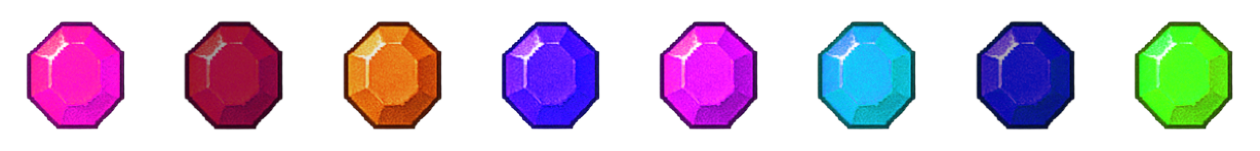

In [11]:
import random
import matplotlib.pyplot as plt

def jitter(img, rng):
    """Random colour change: rotate the hue, then vary brightness. Keeps the shape and the transparency."""
    alpha = img.getchannel("A")
    hsv = np.asarray(img.convert("RGB").convert("HSV")).astype(np.int16)
    hsv[..., 0] = (hsv[..., 0] + rng.randint(0, 255)) % 256       # rotate hue
    hsv[..., 2] = np.clip(hsv[..., 2] * rng.uniform(0.6, 1.4), 0, 255)  # brightness
    rgb = Image.fromarray(hsv.astype(np.uint8), "HSV").convert("RGB")
    return Image.merge("RGBA", (*rgb.split(), alpha))

rng = random.Random(0)
gem = assets["gem"][0]
fig, axes = plt.subplots(1, 8, figsize=(16, 2))
for ax in axes:
    ax.imshow(jitter(gem, rng)); ax.axis("off")
plt.show()

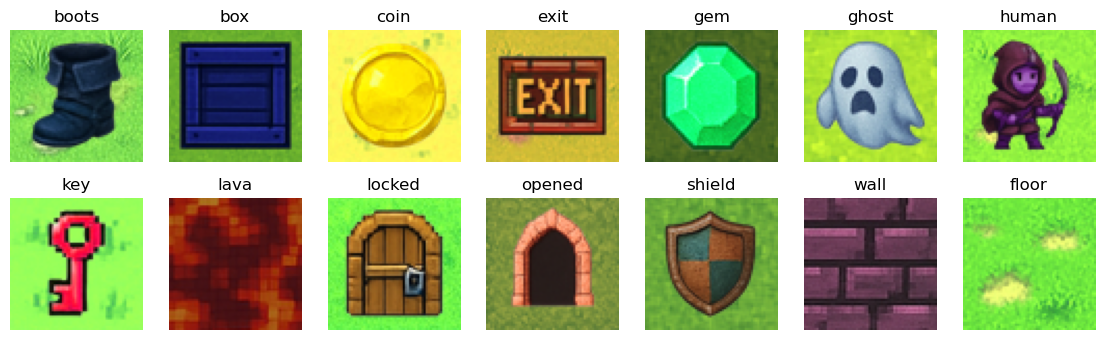

In [12]:
SMALL_HUE = {"floor", "lava", "exit", "coin"}      # colour defines these, so only a tiny shift

def jitter(img, rng, name):
    alpha = img.getchannel("A")
    hsv = np.asarray(img.convert("RGB").convert("HSV")).astype(np.int16)
    span = 20 if name in SMALL_HUE else 255
    hsv[..., 0] = (hsv[..., 0] + rng.randint(-span, span)) % 256
    hsv[..., 2] = np.clip(hsv[..., 2] * rng.uniform(0.6, 1.4), 0, 255)
    rgb = Image.fromarray(hsv.astype(np.uint8), "HSV").convert("RGB")
    return Image.merge("RGBA", (*rgb.split(), alpha))

def make_cell(name, rng, size=64):
    """One training cell showing `name` (or 'floor' for an empty cell)."""
    bg = "wall" if name == "wall" else "floor"          # walls replace the floor tile
    cell = jitter(rng.choice(assets[bg]), rng, bg).resize((size, size))
    if name not in ("floor", "wall"):
        top = jitter(rng.choice(assets[name]), rng, name).resize((size, size))
        cell.alpha_composite(top)
    return cell

rng = random.Random(1)
fig, axes = plt.subplots(2, 7, figsize=(14, 4))
for ax, name in zip(axes.flat, NAMES):
    ax.imshow(make_cell(name, rng)); ax.set_title(name); ax.axis("off")
plt.show()

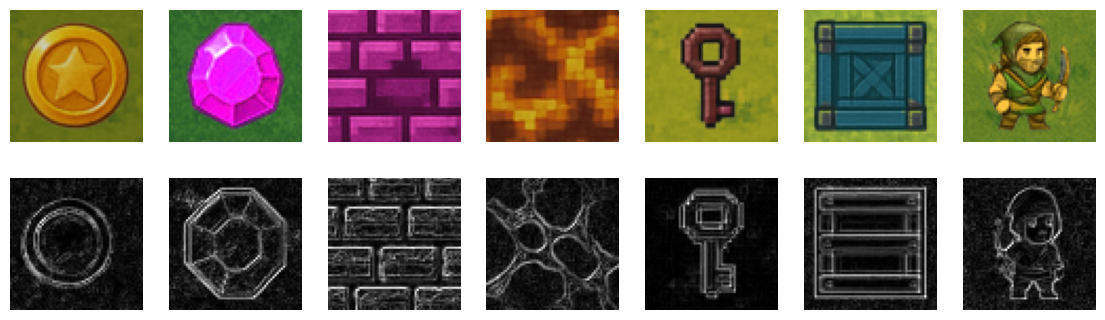

In [13]:
def edge_map(cell):
    """Colour-free edge strength: how much the grey level jumps between neighbouring pixels."""
    g = np.asarray(cell.convert("L"), dtype=np.float32) / 255.0
    dx = np.abs(g[:, 1:] - g[:, :-1])[:-1, :]     # left-right change
    dy = np.abs(g[1:, :] - g[:-1, :])[:, :-1]     # up-down change
    return dx + dy

rng = random.Random(2)
fig, axes = plt.subplots(2, 7, figsize=(14, 4))
for ax, name in zip(axes.flat, ["coin", "gem", "wall", "lava", "key", "box", "human"] * 2):
    cell = make_cell(name, rng)
    ax.imshow(edge_map(cell) if ax in axes[1] else cell, cmap=None if ax in axes[0] else "gray")
    ax.axis("off")
plt.show()

In [14]:
def direction_energy(cell):
    """Mean edge strength in 4 directions: horizontal change, vertical change, 2 diagonals."""
    g = np.asarray(cell.convert("L"), dtype=np.float32) / 255.0
    h  = np.abs(g[:, 1:] - g[:, :-1]).mean()
    v  = np.abs(g[1:, :] - g[:-1, :]).mean()
    d1 = np.abs(g[1:, 1:] - g[:-1, :-1]).mean()
    d2 = np.abs(g[1:, :-1] - g[:-1, 1:]).mean()
    return np.array([h, v, d1, d2])

rng = random.Random(3)
for name in ["wall", "lava", "floor", "box"]:
    E = np.array([direction_energy(make_cell(name, rng)) for _ in range(200)])
    straight = (E[:, 0] + E[:, 1]) / (E[:, 2] + E[:, 3])      # straight edges vs diagonal edges
    print(f"{name:6s} total edge energy {E.sum(1).mean():.3f}   straight/diagonal ratio {straight.mean():.2f} ± {straight.std():.2f}")

wall   total edge energy 0.185   straight/diagonal ratio 0.60 ± 0.03
lava   total edge energy 0.128   straight/diagonal ratio 0.75 ± 0.07
floor  total edge energy 0.096   straight/diagonal ratio 0.79 ± 0.06
box    total edge energy 0.268   straight/diagonal ratio 0.60 ± 0.03


In [15]:
import time
F = 16   # thumbnail size

def cell_features(cell):
    """Colour thumbnail (16x16x3) + edge energy in 4 directions x 4x4 regions = 768 + 64 numbers."""
    thumb = np.asarray(cell.convert("RGB").resize((F, F), Image.BOX), dtype=np.float32) / 255.0
    g = thumb.mean(-1)
    dx = np.abs(g[:, 1:] - g[:, :-1])[:-1, :]
    dy = np.abs(g[1:, :] - g[:-1, :])[:, :-1]
    d1 = np.abs(g[1:, 1:] - g[:-1, :-1])
    d2 = np.abs(g[1:, :-1] - g[:-1, 1:])
    tex = [d[:12, :12].reshape(4, 3, 4, 3).mean((1, 3)).ravel() for d in (dx, dy, d1, d2)]
    return np.concatenate([thumb.ravel(), np.concatenate(tex) * 4.0])

def make_dataset(n, seed):
    rng = random.Random(seed)
    X = np.empty((n, F * F * 3 + 64), dtype=np.float32)
    y = np.empty(n, dtype=np.int64)
    for i in range(n):
        k = rng.randrange(len(NAMES))                 # each class equally likely
        X[i] = cell_features(make_cell(NAMES[k], rng))
        y[i] = k
    return X, y

t = time.time()
X, y = make_dataset(3000, seed=0)
print("X", X.shape, "y", y.shape, f"({time.time() - t:.1f} s)")
print("cells per class:", np.bincount(y))

X (3000, 832) y (3000,) (2.6 s)
cells per class: [225 218 203 218 224 214 204 210 206 221 223 210 214 210]


In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

# 1) hide 25% of every entity's looks, for testing only
split_rng = random.Random(0)
train_assets, test_assets = {}, {}
for name in NAMES:
    looks = list(assets[name]); split_rng.shuffle(looks)
    k = max(1, round(len(looks) * 0.25))
    test_assets[name], train_assets[name] = looks[:k], looks[k:]

# 2) make_cell now takes the pool of looks it may draw from
def make_cell(name, rng, pool, size=64):
    bg = "wall" if name == "wall" else "floor"
    cell = jitter(rng.choice(pool[bg]), rng, bg).resize((size, size))
    if name not in ("floor", "wall"):
        cell.alpha_composite(jitter(rng.choice(pool[name]), rng, name).resize((size, size)))
    return cell

def make_dataset(n, seed, pool):
    rng = random.Random(seed)
    X = np.empty((n, F * F * 3 + 64), dtype=np.float32); y = np.empty(n, dtype=np.int64)
    for i in range(n):
        k = rng.randrange(len(NAMES))
        X[i] = cell_features(make_cell(NAMES[k], rng, pool)); y[i] = k
    return X, y

Xtr, ytr = make_dataset(15000, 1, train_assets)
Xte, yte = make_dataset(3000, 2, test_assets)       # unseen looks only

for label, model in [("linear", LogisticRegression(max_iter=300)),
                     ("small net", MLPClassifier((96,), max_iter=60, random_state=0))]:
    t = time.time(); model.fit(Xtr, ytr)
    print(f"{label:9s} train acc {model.score(Xtr, ytr):.3f}   UNSEEN-looks acc {model.score(Xte, yte):.3f}   ({time.time() - t:.0f} s)")

linear    train acc 1.000   UNSEEN-looks acc 0.991   (1 s)
small net train acc 1.000   UNSEEN-looks acc 0.991   (4 s)


In [17]:
from collections import Counter

lin = LogisticRegression(max_iter=300).fit(Xtr, ytr)
pred = lin.predict(Xte)
errors = Counter((NAMES[a], NAMES[b]) for a, b in zip(yte, pred) if a != b)
print("wrong cells:", sum(errors.values()), "of", len(yte))
for (truth, guess), n in errors.most_common(10):
    print(f"  {truth:7s} read as {guess:7s} x{n}")

wrong cells: 28 of 3000
  shield  read as gem     x28


In [18]:
def cell_features(cell):
    """Colour thumbnail (16x16x3) + edge energy in 4 directions x 8x8 regions = 768 + 256 numbers."""
    thumb = np.asarray(cell.convert("RGB").resize((F, F), Image.BOX), dtype=np.float32) / 255.0
    g = thumb.mean(-1)
    dx = np.abs(g[:, 1:] - g[:, :-1])[:-1, :]
    dy = np.abs(g[1:, :] - g[:-1, :])[:, :-1]
    d1 = np.abs(g[1:, 1:] - g[:-1, :-1])
    d2 = np.abs(g[1:, :-1] - g[:-1, 1:])
    tex = [d[:14, :14].reshape(7, 2, 7, 2).mean((1, 3)).ravel() for d in (dx, dy, d1, d2)]   # 7x7 regions
    return np.concatenate([thumb.ravel(), np.concatenate(tex) * 4.0])

def make_dataset(n, seed, pool):
    rng = random.Random(seed)
    X = np.empty((n, F * F * 3 + 4 * 49), dtype=np.float32); y = np.empty(n, dtype=np.int64)
    for i in range(n):
        k = rng.randrange(len(NAMES))
        X[i] = cell_features(make_cell(NAMES[k], rng, pool)); y[i] = k
    return X, y

Xtr, ytr = make_dataset(15000, 1, train_assets)
Xte, yte = make_dataset(3000, 2, test_assets)
lin = LogisticRegression(max_iter=300).fit(Xtr, ytr)
pred = lin.predict(Xte)
print("unseen-looks acc", round(lin.score(Xte, yte), 4))
for (truth, guess), n in Counter((NAMES[a], NAMES[b]) for a, b in zip(yte, pred) if a != b).most_common(5):
    print(f"  {truth:7s} read as {guess:7s} x{n}")

unseen-looks acc 0.9947
  shield  read as gem     x16


In [19]:
base_features = cell_features          # keep the previous version as the base

def extra_features(cell):
    t = cell.convert("RGB").resize((F, F), Image.BOX)
    hsv = np.asarray(t.convert("HSV"), dtype=np.float32) / 255.0
    hue, sat, val = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    bins = np.minimum((hue * 8).astype(int), 7)
    mass = np.bincount(bins.ravel(), weights=(sat * val).ravel(), minlength=8)
    mass = np.sort(mass / (mass.sum() + 1e-6))[::-1]            # how many hues, not which ones
    rgb = np.asarray(t, dtype=np.float32) / 255.0
    ring = np.ones((F, F), bool); ring[3:-3, 3:-3] = False
    rim_vs_centre = np.abs(rgb[ring].mean(0) - rgb[~ring].mean(0))
    return np.concatenate([mass, rim_vs_centre, [sat.std()]])

def cell_features(cell):
    return np.concatenate([base_features(cell), extra_features(cell)])

def make_dataset(n, seed, pool):
    rng = random.Random(seed)
    X, y = [], []
    for _ in range(n):
        k = rng.randrange(len(NAMES))
        X.append(cell_features(make_cell(NAMES[k], rng, pool))); y.append(k)
    return np.array(X, dtype=np.float32), np.array(y)

Xtr, ytr = make_dataset(15000, 1, train_assets)
Xte, yte = make_dataset(3000, 2, test_assets)
lin = LogisticRegression(max_iter=500).fit(Xtr, ytr)
pred = lin.predict(Xte)
print("features per cell:", Xtr.shape[1], "  unseen-looks acc", round(lin.score(Xte, yte), 4))
for (truth, guess), n in Counter((NAMES[a], NAMES[b]) for a, b in zip(yte, pred) if a != b).most_common(5):
    print(f"  {truth:7s} read as {guess:7s} x{n}")

features per cell: 976   unseen-looks acc 0.9947
  shield  read as gem     x16


15 of 400 hidden-look shields misread


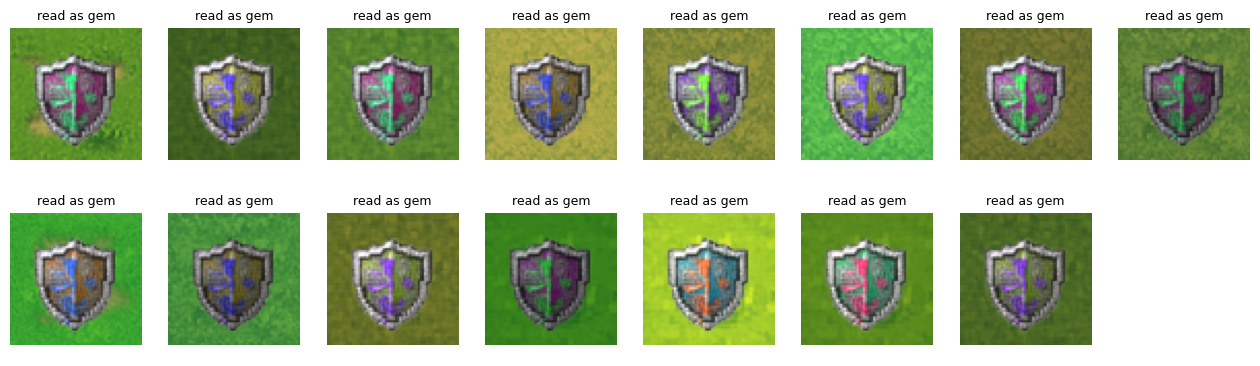

hidden shield looks:


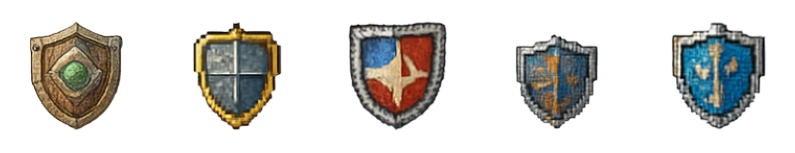

In [20]:
rng = random.Random(5)
shown = []
for _ in range(400):
    cell = make_cell("shield", rng, test_assets)
    guess = NAMES[lin.predict(cell_features(cell).reshape(1, -1))[0]]
    if guess != "shield":
        shown.append((cell, guess))
print(f"{len(shown)} of 400 hidden-look shields misread")

fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for ax in axes.flat: ax.axis("off")
for ax, (cell, guess) in zip(axes.flat, shown[:16]):
    ax.imshow(cell); ax.set_title(f"read as {guess}", fontsize=9)
plt.show()

print("hidden shield looks:")
fig, axes = plt.subplots(1, len(test_assets["shield"]), figsize=(2 * len(test_assets["shield"]), 2))
for ax, img in zip(np.atleast_1d(axes), test_assets["shield"]):
    ax.imshow(img); ax.axis("off")
plt.show()

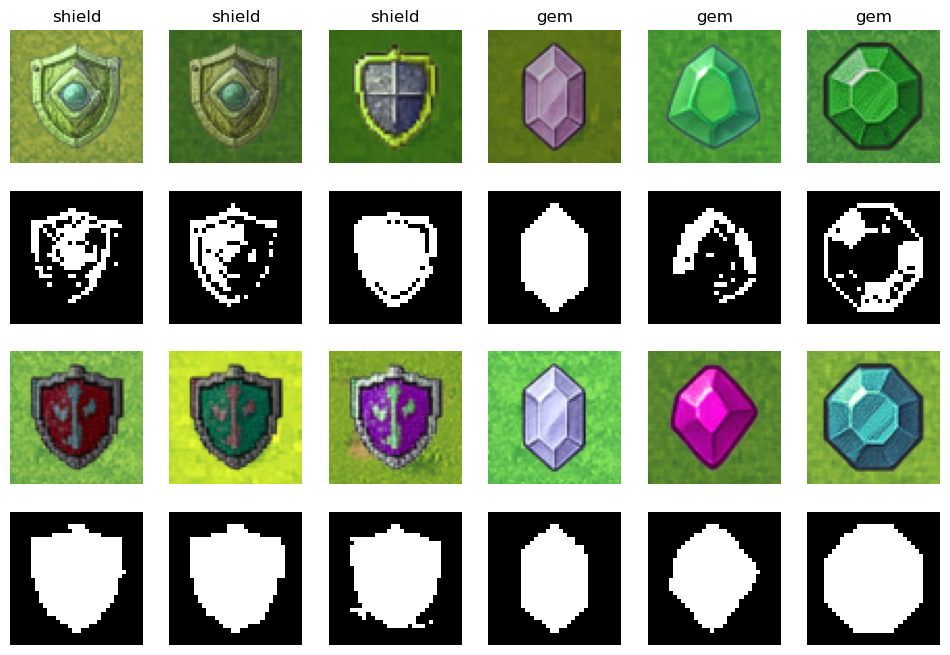

features per cell: 1041   unseen-looks acc 0.9973
  shield  read as gem     x8


In [21]:
def silhouette(cell):
    """Object-vs-background mask: pixels that differ from the typical colour of the cell's border."""
    rgb = np.asarray(cell.convert("RGB").resize((32, 32), Image.BOX), dtype=np.float32) / 255.0
    border = np.ones((32, 32), bool); border[3:-3, 3:-3] = False
    ref = np.median(rgb[border], axis=0)
    return (np.abs(rgb - ref).max(-1) > 0.18).astype(np.float32)

def shape_features(cell):
    m = silhouette(cell)
    grid = m.reshape(8, 4, 8, 4).mean((1, 3)).ravel()            # 8x8 blocks, how filled each is
    symmetry = np.abs(m - m[:, ::-1]).mean()                     # 0 = perfectly left-right symmetric
    return np.concatenate([grid, [symmetry]])

# look at the silhouettes
rng = random.Random(7)
fig, axes = plt.subplots(4, 6, figsize=(12, 8))
for c, name in enumerate(["shield"] * 3 + ["gem"] * 3):
    cell = make_cell(name, rng, test_assets)
    axes[0, c].imshow(cell); axes[0, c].set_title(name); axes[1, c].imshow(silhouette(cell), cmap="gray")
    cell = make_cell(name, rng, test_assets)
    axes[2, c].imshow(cell); axes[3, c].imshow(silhouette(cell), cmap="gray")
for ax in axes.flat: ax.axis("off")
plt.show()

def cell_features(cell):
    return np.concatenate([base_features(cell), extra_features(cell), shape_features(cell)])

Xtr, ytr = make_dataset(15000, 1, train_assets)
Xte, yte = make_dataset(3000, 2, test_assets)
lin = LogisticRegression(max_iter=500).fit(Xtr, ytr)
pred = lin.predict(Xte)
print("features per cell:", Xtr.shape[1], "  unseen-looks acc", round(lin.score(Xte, yte), 4))
for (truth, guess), n in Counter((NAMES[a], NAMES[b]) for a, b in zip(yte, pred) if a != b).most_common(5):
    print(f"  {truth:7s} read as {guess:7s} x{n}")

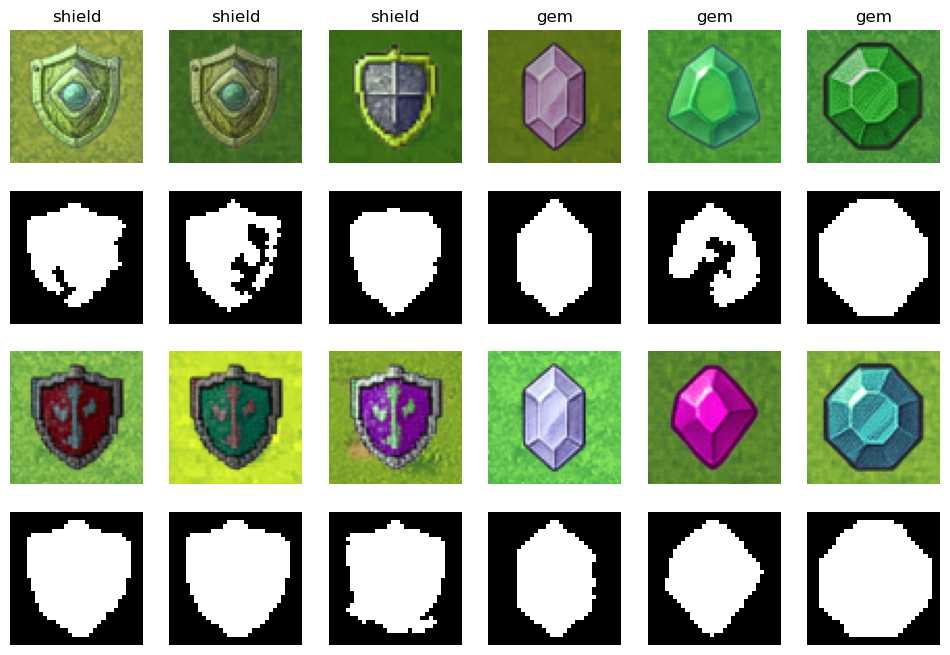

data: 25 s
features per cell: 1041   unseen-looks acc 0.9953
  shield  read as gem     x14


In [22]:
from collections import deque

def silhouette(cell):
    rgb = np.asarray(cell.convert("RGB").resize((32, 32), Image.BOX), dtype=np.float32) / 255.0
    border = np.ones((32, 32), bool); border[3:-3, 3:-3] = False
    ref = np.median(rgb[border], axis=0)
    m = np.abs(rgb - ref).max(-1) > 0.18                       # differs from the surroundings
    g = rgb.mean(-1)
    m[:, 1:] |= np.abs(g[:, 1:] - g[:, :-1]) > 0.2             # outline pixels (sharp brightness jumps)
    m[1:, :] |= np.abs(g[1:, :] - g[:-1, :]) > 0.2
    grown = m.copy()                                           # grow by one pixel to close tiny gaps
    grown[1:, :] |= m[:-1, :]; grown[:-1, :] |= m[1:, :]
    grown[:, 1:] |= m[:, :-1]; grown[:, :-1] |= m[:, 1:]
    grown[:2, :] = grown[-2:, :] = False; grown[:, :2] = grown[:, -2:] = False   # the very edge is always background
    outside = np.zeros((32, 32), bool)
    queue = deque((y, x) for y in range(32) for x in range(32)
                  if (y in (0, 31) or x in (0, 31)))
    for p in queue: outside[p] = True
    while queue:                                               # flood the background inwards
        y, x = queue.popleft()
        for ny, nx in ((y - 1, x), (y + 1, x), (y, x - 1), (y, x + 1)):
            if 0 <= ny < 32 and 0 <= nx < 32 and not outside[ny, nx] and not grown[ny, nx]:
                outside[ny, nx] = True
                queue.append((ny, nx))
    return (~outside).astype(np.float32)                       # object = everything the flood didn't reach

rng = random.Random(7)
fig, axes = plt.subplots(4, 6, figsize=(12, 8))
for c, name in enumerate(["shield"] * 3 + ["gem"] * 3):
    cell = make_cell(name, rng, test_assets)
    axes[0, c].imshow(cell); axes[0, c].set_title(name); axes[1, c].imshow(silhouette(cell), cmap="gray")
    cell = make_cell(name, rng, test_assets)
    axes[2, c].imshow(cell); axes[3, c].imshow(silhouette(cell), cmap="gray")
for ax in axes.flat: ax.axis("off")
plt.show()

t = time.time()
Xtr, ytr = make_dataset(15000, 1, train_assets)
Xte, yte = make_dataset(3000, 2, test_assets)
print(f"data: {time.time() - t:.0f} s")
lin = LogisticRegression(max_iter=500).fit(Xtr, ytr)
pred = lin.predict(Xte)
print("features per cell:", Xtr.shape[1], "  unseen-looks acc", round(lin.score(Xte, yte), 4))
for (truth, guess), n in Counter((NAMES[a], NAMES[b]) for a, b in zip(yte, pred) if a != b).most_common(5):
    print(f"  {truth:7s} read as {guess:7s} x{n}")

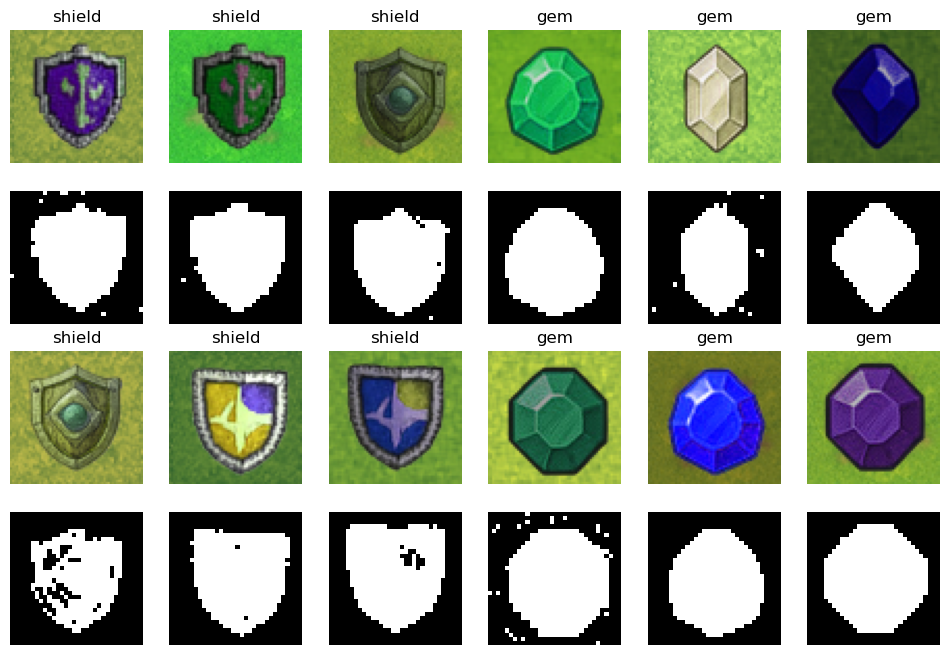

features per cell: 1041   unseen-looks acc 0.9947
  shield  read as gem     x12
  boots   read as locked  x4


In [23]:
def jitter(img, rng, name):
    alpha = img.getchannel("A")
    hsv = np.asarray(img.convert("RGB").convert("HSV")).astype(np.int16)
    span = 20 if name in SMALL_HUE else 255
    hsv[..., 0] = (hsv[..., 0] + rng.randint(-span, span)) % 256
    hsv[..., 2] = np.clip(hsv[..., 2] * rng.uniform(0.6, 1.4), 0, 255)
    rgb = Image.fromarray(hsv.astype(np.uint8), "HSV").convert("RGB")
    out = Image.merge("RGBA", (*rgb.split(), alpha))
    if name != "exit" and rng.random() < 0.3:                  # facing left or right
        out = out.transpose(Image.FLIP_LEFT_RIGHT)
    return out

def make_cell(name, rng, pool, size=64):
    """Returns (cell, floor): the cell image, and the plain floor tile of this 'level'."""
    floor = jitter(rng.choice(pool["floor"]), rng, "floor").resize((size, size))
    if name == "wall":
        cell = jitter(rng.choice(pool["wall"]), rng, "wall").resize((size, size))
    else:
        cell = floor.copy()
        if name != "floor":
            cell.alpha_composite(jitter(rng.choice(pool[name]), rng, name).resize((size, size)))
    dx, dy = rng.randint(0, 2), rng.randint(0, 2)               # renderer cuts cells at slightly different offsets
    cell = Image.fromarray(np.roll(np.asarray(cell), (dy, dx), axis=(0, 1)))
    return cell, floor

def floor_mask(cell, floor):
    a = np.asarray(cell.convert("RGB").resize((32, 32), Image.BOX), dtype=np.float32) / 255.0
    b = np.asarray(floor.convert("RGB").resize((32, 32), Image.BOX), dtype=np.float32) / 255.0
    return (np.abs(a - b).max(-1) > 0.12).astype(np.float32)   # which pixels differ from the floor

def shape_features(cell, floor):
    m = floor_mask(cell, floor)
    grid = m.reshape(8, 4, 8, 4).mean((1, 3)).ravel()
    symmetry = np.abs(m - m[:, ::-1]).mean()
    return np.concatenate([grid, [symmetry]])

def cell_features(cell, floor):
    return np.concatenate([base_features(cell), extra_features(cell), shape_features(cell, floor)])

def make_dataset(n, seed, pool):
    rng = random.Random(seed)
    X, y = [], []
    for _ in range(n):
        k = rng.randrange(len(NAMES))
        cell, floor = make_cell(NAMES[k], rng, pool)
        X.append(cell_features(cell, floor)); y.append(k)
    return np.array(X, dtype=np.float32), np.array(y)

# look at the masks
rng = random.Random(7)
fig, axes = plt.subplots(4, 6, figsize=(12, 8))
for c, name in enumerate(["shield"] * 3 + ["gem"] * 3):
    for r in (0, 2):
        cell, floor = make_cell(name, rng, test_assets)
        axes[r, c].imshow(cell); axes[r, c].set_title(name); axes[r + 1, c].imshow(floor_mask(cell, floor), cmap="gray")
for ax in axes.flat: ax.axis("off")
plt.show()

Xtr, ytr = make_dataset(15000, 1, train_assets)
Xte, yte = make_dataset(3000, 2, test_assets)
lin = LogisticRegression(max_iter=500).fit(Xtr, ytr)
pred = lin.predict(Xte)
print("features per cell:", Xtr.shape[1], "  unseen-looks acc", round(lin.score(Xte, yte), 4))
for (truth, guess), n in Counter((NAMES[a], NAMES[b]) for a, b in zip(yte, pred) if a != b).most_common(5):
    print(f"  {truth:7s} read as {guess:7s} x{n}")

In [24]:
groups = {"colour thumbnail": slice(0, 768), "edge directions": slice(768, 964),
          "colour variety": slice(964, 976), "shape (vs floor)": slice(976, 1041)}

def cols(*names):
    return np.concatenate([np.arange(1041)[groups[n]] for n in names])

trials = [
    ("thumbnail only",              cols("colour thumbnail"),                                  1.0),
    ("edges only",                  cols("edge directions"),                                   1.0),
    ("shape only",                  cols("shape (vs floor)"),                                  1.0),
    ("edges + shape",               cols("edge directions", "shape (vs floor)"),               1.0),
    ("edges + shape + variety",     cols("edge directions", "shape (vs floor)", "colour variety"), 1.0),
    ("all features",                np.arange(1041),                                           1.0),
    ("all features, C=0.1",         np.arange(1041),                                           0.1),
    ("edges+shape+variety, C=0.1",  cols("edge directions", "shape (vs floor)", "colour variety"), 0.1),
]
for label, c, C in trials:
    m = LogisticRegression(max_iter=500, C=C).fit(Xtr[:, c], ytr)
    p = m.predict(Xte[:, c])
    top = Counter((NAMES[a], NAMES[b]) for a, b in zip(yte, p) if a != b).most_common(2)
    print(f"{label:28s} unseen acc {m.score(Xte[:, c], yte):.4f}   {top}")

thumbnail only               unseen acc 0.9840   [(('shield', 'gem'), 15), (('key', 'floor'), 11)]
edges only                   unseen acc 0.9753   [(('lava', 'floor'), 19), (('floor', 'lava'), 16)]
shape only                   unseen acc 0.8957   [(('wall', 'lava'), 183), (('shield', 'gem'), 19)]
edges + shape                unseen acc 0.9893   [(('boots', 'locked'), 11), (('human', 'shield'), 6)]
edges + shape + variety      unseen acc 0.9907   [(('boots', 'locked'), 9), (('gem', 'human'), 6)]
all features                 unseen acc 0.9947   [(('shield', 'gem'), 12), (('boots', 'locked'), 4)]
all features, C=0.1          unseen acc 0.9950   [(('shield', 'gem'), 13), (('boots', 'locked'), 2)]
edges+shape+variety, C=0.1   unseen acc 0.9873   [(('boots', 'locked'), 12), (('gem', 'human'), 11)]


In [25]:
def split_looks(seed, frac=0.25):
    r = random.Random(seed); tr, te = {}, {}
    for name in NAMES:
        looks = list(assets[name]); r.shuffle(looks)
        k = max(1, round(len(looks) * frac))
        te[name], tr[name] = looks[:k], looks[k:]
    return tr, te

results = {"linear": [], "small net": []}
for s in (10, 11, 12):
    tr_pool, te_pool = split_looks(s)
    Xa, ya = make_dataset(15000, s, tr_pool)
    Xb, yb = make_dataset(3000, s + 100, te_pool)
    for label, model in [("linear", LogisticRegression(max_iter=500)),
                         ("small net", MLPClassifier((96,), max_iter=60, random_state=0))]:
        model.fit(Xa, ya)
        acc = model.score(Xb, yb); results[label].append(acc)
        errs = Counter((NAMES[a], NAMES[b]) for a, b in zip(yb, model.predict(Xb)) if a != b).most_common(2)
        print(f"split {s}  {label:9s} {acc:.4f}  {errs}")
for label, v in results.items():
    print(f"{label:9s} mean {np.mean(v):.4f}   worst {min(v):.4f}")

split 10  linear    0.9907  [(('coin', 'gem'), 11), (('shield', 'gem'), 10)]
split 10  small net 0.9923  [(('shield', 'gem'), 10), (('coin', 'gem'), 7)]
split 11  linear    0.9993  [(('boots', 'locked'), 2)]
split 11  small net 0.9983  [(('boots', 'locked'), 5)]
split 12  linear    0.9950  [(('gem', 'shield'), 5), (('shield', 'gem'), 4)]
split 12  small net 0.9963  [(('shield', 'gem'), 5), (('gem', 'shield'), 2)]
linear    mean 0.9950   worst 0.9907
small net mean 0.9957   worst 0.9923


In [26]:
import os, shutil
from itertools import product
from pathlib import Path
import utils
from public_levels.catalog import PUBLIC_GAMEPLAY_LEVEL_BUILDERS, PUBLIC_BOSS_LEVEL_BUILDERS

# ---- the two classifiers, trained on the training looks only
Xtr, ytr = make_dataset(15000, 1, train_assets)
stage1 = LogisticRegression(max_iter=500).fit(Xtr[:, :976], ytr)   # colour + edges: finds the floor
stage2 = LogisticRegression(max_iter=500).fit(Xtr, ytr)            # + shape against the floor tile

# ---- parser pieces
def split_cells(image, W, H):
    ih, iw = image.shape[:2]
    return [Image.fromarray(np.ascontiguousarray(image[y*ih//H:(y+1)*ih//H, x*iw//W:(x+1)*iw//W, :3]))
            for y in range(H) for x in range(W)]

def cluster_by_look(T, tol=0.03):
    """Cells that look (almost) identical are grouped together."""
    reps, members = [], []
    for i in range(len(T)):
        for r, rep in enumerate(reps):
            if np.abs(T[i] - T[rep]).mean() < tol:
                members[r].append(i); break
        else:
            reps.append(i); members.append([i])
    return members

def decide(P, members, first_turn=True, max_uncertain=9):
    n = len(P); P = np.clip(P, 1e-6, 1.0)
    idx = {c: i for i, c in enumerate(NAMES)}
    out = [None] * n; taken = set()
    for name in ("human", "exit"):                     # exactly one agent and one exit
        best = max((i for i in range(n) if i not in taken), key=lambda i: P[i, idx[name]])
        out[best] = {name}; taken.add(best)
    clusters = []
    for m in members:
        m = [i for i in m if i not in taken]
        if not m: continue
        p = P[m].mean(0).copy()
        p[idx["human"]] = p[idx["exit"]] = 0.0
        if first_turn:                                 # every door starts locked
            p[idx["locked"]] += p[idx["opened"]]; p[idx["opened"]] = 0.0
        p = p / p.sum()
        clusters.append((m, np.log(np.clip(p, 1e-9, 1.0)) * len(m), p))
    choice = [int(np.argmax(c[2])) for c in clusters]
    def counts(ch):
        keys = sum(len(c[0]) for c, k in zip(clusters, ch) if k == idx["key"])
        doors = sum(len(c[0]) for c, k in zip(clusters, ch) if k in (idx["locked"], idx["opened"]))
        return keys, doors
    if counts(choice)[0] != counts(choice)[1]:         # keys must equal doors: relabel the shakiest clusters
        shaky = sorted(range(len(clusters)), key=lambda j: clusters[j][2][choice[j]])[:max_uncertain]
        options = [[int(k) for k in np.argsort(-clusters[j][2])[:3] if clusters[j][2][k] > 0.01] for j in shaky]
        best, best_score = None, -1e18
        for combo in product(*options):
            ch = list(choice)
            for j, k in zip(shaky, combo): ch[j] = k
            if counts(ch)[0] != counts(ch)[1]: continue
            score = sum(clusters[j][1][ch[j]] for j in range(len(clusters)))
            if score > best_score: best, best_score = ch, score
        if best is not None: choice = best
    for (m, _, _), k in zip(clusters, choice):
        for i in m: out[i] = set() if NAMES[k] == "floor" else {NAMES[k]}
    return out

def parse_image(image, W, H, first_turn=True):
    cells = split_cells(image, W, H)
    F1 = np.array([np.concatenate([base_features(c), extra_features(c)]) for c in cells], dtype=np.float32)
    members = cluster_by_look(F1[:, :768])                           # first 768 numbers = colour thumbnail
    P1 = stage1.predict_proba(F1)
    floor_group = max(members, key=lambda m: P1[m, NAMES.index("floor")].mean())
    floor_tile = cells[floor_group[0]]                               # this level's floor picture
    F2 = np.array([cell_features(c, floor_tile) for c in cells], dtype=np.float32)
    return decide(stage2.predict_proba(F2), members, first_turn)

def truth_cells(state):
    W, H = state.width, state.height
    t = [set() for _ in range(W * H)]
    for eid, p in state.position.items():
        nm = state.appearance[eid].name
        if nm == "door": nm = "locked" if eid in state.locked else "opened"
        if nm in NAMES and nm != "floor": t[p.y * W + p.x].add(nm)
    return t

# ---- an asset folder holding ONLY the hidden looks, so the real renderer draws unseen looks
HELD = Path("heldout_assets_scratch")
shutil.rmtree(HELD, ignore_errors=True)
for name, looks in test_assets.items():
    (HELD / name).mkdir(parents=True)
    for k, img in enumerate(looks): img.save(HELD / name / f"{name}_{k + 1}.png")
shutil.copytree(Path(DEFAULT_ASSET_ROOT) / "sleeping", HELD / "sleeping")

# ---- score the parser on the real renderer
old_root = utils.DEFAULT_ASSET_ROOT
utils.DEFAULT_ASSET_ROOT = str(HELD.resolve())
try:
    cells_n = cells_ok = levels_n = levels_ok = 0; parse_time = 0.0; bad = []
    for label, builder in {**PUBLIC_GAMEPLAY_LEVEL_BUILDERS, **PUBLIC_BOSS_LEVEL_BUILDERS}.items():
        for seed in (0, 1, 2):
            env = utils.create_env(builder, observation_type="image", seed=seed)
            obs, _ = env.reset()
            W, H = obs["info"]["config"]["width"], obs["info"]["config"]["height"]
            t = time.time(); pred = parse_image(obs["image"], W, H); parse_time += time.time() - t
            real = truth_cells(env.state)
            wrong = [((i % W, i // W), real[i], pred[i]) for i in range(len(real)) if real[i] != pred[i]]
            cells_n += len(real); cells_ok += len(real) - len(wrong)
            levels_n += 1; levels_ok += (not wrong)
            if wrong: bad.append((label, seed, wrong[:3]))
finally:
    utils.DEFAULT_ASSET_ROOT = old_root

print(f"cells right {cells_ok}/{cells_n}   levels read perfectly {levels_ok}/{levels_n}   avg parse {1000 * parse_time / levels_n:.0f} ms/level")
for b in bad: print("  wrong:", b)

cells right 11061/11064   levels read perfectly 69/72   avg parse 45 ms/level
  wrong: ('A4 Key and Door', 2, [((2, 3), {'key'}, set())])
  wrong: ('B4 Measure Twice and Cut Once', 2, [((5, 7), {'key'}, set())])
  wrong: ('B10 Khoa Was Here', 2, [((8, 6), {'key'}, set())])


In [27]:
def find_floor(cells):
    F1 = np.array([np.concatenate([base_features(c), extra_features(c)]) for c in cells], dtype=np.float32)
    members = cluster_by_look(F1[:, :768])
    P1 = stage1.predict_proba(F1)
    group = max(members, key=lambda m: P1[m, NAMES.index("floor")].mean())
    return cells[group[0]]

utils.DEFAULT_ASSET_ROOT = str(HELD.resolve())
floor_areas, object_areas = [], []
try:
    for label, builder in {**PUBLIC_GAMEPLAY_LEVEL_BUILDERS, **PUBLIC_BOSS_LEVEL_BUILDERS}.items():
        for seed in (0, 1, 2):
            env = utils.create_env(builder, observation_type="image", seed=seed)
            obs, _ = env.reset()
            W, H = obs["info"]["config"]["width"], obs["info"]["config"]["height"]
            cells = split_cells(obs["image"], W, H)
            tile = find_floor(cells)
            real = truth_cells(env.state)
            for i, c in enumerate(cells):
                area = floor_mask(c, tile).mean()
                if real[i]:
                    object_areas.append((area, label, seed, (i % W, i // W), sorted(real[i])[0]))
                else:
                    floor_areas.append(area)
finally:
    utils.DEFAULT_ASSET_ROOT = old_root

fa = np.array(floor_areas)
print(f"empty-floor cells: {len(fa)}   area: mean {fa.mean():.4f}   99.9th percentile {np.percentile(fa, 99.9):.4f}   max {fa.max():.4f}")
object_areas.sort()
print("smallest object areas (the hardest to tell from floor):")
for a in object_areas[:8]:
    print(f"  area {a[0]:.4f}  {a[4]:7s} {a[1]} seed {a[2]} cell {a[3]}")

empty-floor cells: 7104   area: mean 0.0087   99.9th percentile 0.0732   max 0.0732
smallest object areas (the hardest to tell from floor):
  area 0.1895  key     A4 Key and Door seed 2 cell (2, 3)
  area 0.1924  key     B4 Measure Twice and Cut Once seed 1 cell (5, 7)
  area 0.1963  key     B4 Measure Twice and Cut Once seed 2 cell (5, 7)
  area 0.1982  key     B4 Measure Twice and Cut Once seed 2 cell (3, 13)
  area 0.2021  key     B4 Measure Twice and Cut Once seed 1 cell (3, 13)
  area 0.2031  key     B10 Khoa Was Here seed 2 cell (8, 6)
  area 0.2041  key     B10 Khoa Was Here seed 1 cell (8, 6)
  area 0.2041  key     B4 Measure Twice and Cut Once seed 2 cell (12, 9)


In [28]:
AREA_CUTOFF = 0.12     # Step 15: floor cells differ from the floor tile by < 0.074, every object by > 0.18

def parse_image(image, W, H, first_turn=True):
    cells = split_cells(image, W, H)
    F1 = np.array([np.concatenate([base_features(c), extra_features(c)]) for c in cells], dtype=np.float32)
    members = cluster_by_look(F1[:, :768])
    P1 = stage1.predict_proba(F1)
    floor_group = max(members, key=lambda m: P1[m, NAMES.index("floor")].mean())
    floor_tile = cells[floor_group[0]]
    F2 = np.array([cell_features(c, floor_tile) for c in cells], dtype=np.float32)
    P2 = stage2.predict_proba(F2)
    area = np.array([floor_mask(c, floor_tile).mean() for c in cells])
    P2[area > AREA_CUTOFF, NAMES.index("floor")] = 0.0     # something is drawn here, so it can't be floor
    P2 /= P2.sum(1, keepdims=True)
    return decide(P2, members, first_turn)

def score_parser(seeds):
    old_root = utils.DEFAULT_ASSET_ROOT
    utils.DEFAULT_ASSET_ROOT = str(HELD.resolve())
    cells_n = cells_ok = levels_n = levels_ok = 0; parse_time = 0.0; bad = []
    try:
        for label, builder in {**PUBLIC_GAMEPLAY_LEVEL_BUILDERS, **PUBLIC_BOSS_LEVEL_BUILDERS}.items():
            for seed in seeds:
                env = utils.create_env(builder, observation_type="image", seed=seed)
                obs, _ = env.reset()
                W, H = obs["info"]["config"]["width"], obs["info"]["config"]["height"]
                t = time.time(); pred = parse_image(obs["image"], W, H); parse_time += time.time() - t
                real = truth_cells(env.state)
                wrong = [((i % W, i // W), real[i], pred[i]) for i in range(len(real)) if real[i] != pred[i]]
                cells_n += len(real); cells_ok += len(real) - len(wrong)
                levels_n += 1; levels_ok += (not wrong)
                if wrong: bad.append((label, seed, wrong[:3]))
    finally:
        utils.DEFAULT_ASSET_ROOT = old_root
    print(f"seeds {tuple(seeds)}: cells {cells_ok}/{cells_n}   levels perfect {levels_ok}/{levels_n}   "
          f"avg parse {1000 * parse_time / levels_n:.0f} ms")
    for b in bad: print("  wrong:", b)

score_parser((0, 1, 2))          # the same renders as Step 14
score_parser((3, 4, 5, 6, 7))    # new seeds, new looks drawn from the hidden set

seeds (0, 1, 2): cells 11061/11064   levels perfect 69/72   avg parse 52 ms
  wrong: ('A4 Key and Door', 2, [((2, 3), {'key'}, set())])
  wrong: ('B4 Measure Twice and Cut Once', 2, [((5, 7), {'key'}, set())])
  wrong: ('B10 Khoa Was Here', 2, [((8, 6), {'key'}, set())])
seeds (3, 4, 5, 6, 7): cells 18437/18440   levels perfect 117/120   avg parse 52 ms
  wrong: ('A4 Key and Door', 5, [((2, 3), {'key'}, set())])
  wrong: ('B4 Measure Twice and Cut Once', 5, [((5, 7), {'key'}, set())])
  wrong: ('B10 Khoa Was Here', 5, [((8, 6), {'key'}, set())])


In [29]:
def parse_image(image, W, H, first_turn=True):
    cells = split_cells(image, W, H)
    F1 = np.array([np.concatenate([base_features(c), extra_features(c)]) for c in cells], dtype=np.float32)
    members = cluster_by_look(F1[:, :768])
    P1 = stage1.predict_proba(F1)
    floor_group = max(members, key=lambda m: P1[m, NAMES.index("floor")].mean())
    thumbs = F1[floor_group, :768]                                   # the floor tile = the group member closest to the typical one
    typical = np.median(thumbs, axis=0)
    floor_tile = cells[floor_group[int(np.argmin(np.abs(thumbs - typical).mean(1)))]]

    F2 = np.array([cell_features(c, floor_tile) for c in cells], dtype=np.float32)
    P2 = stage2.predict_proba(F2)
    area = np.array([floor_mask(c, floor_tile).mean() for c in cells])
    drawn = area > AREA_CUTOFF                                       # something is drawn here
    P2[drawn, NAMES.index("floor")] = 0.0
    P2 /= P2.sum(1, keepdims=True)

    split = []                                                       # never let a drawn cell share a group with plain floor
    for m in members:
        for part in ([i for i in m if drawn[i]], [i for i in m if not drawn[i]]):
            if part: split.append(part)
    return decide(P2, split, first_turn)

score_parser((0, 1, 2))
score_parser((3, 4, 5, 6, 7))

seeds (0, 1, 2): cells 11064/11064   levels perfect 72/72   avg parse 53 ms
seeds (3, 4, 5, 6, 7): cells 18440/18440   levels perfect 120/120   avg parse 53 ms


In [30]:
import base64, io

Xall, yall = make_dataset(30000, 77, assets)                       # ALL looks this time
final1 = LogisticRegression(max_iter=500).fit(Xall[:, :976], yall) # finds the floor
final2 = LogisticRegression(max_iter=500).fit(Xall, yall)          # reads each cell against the floor

def pack(model):
    """Weights as int8 (+ one scale), biases as float16: small enough to paste."""
    W = model.coef_.T.astype(np.float32)                           # (features, 14)
    s = float(np.abs(W).max() / 127.0)
    return dict(W=np.round(W / s).astype(np.int8), s=np.array(s, dtype=np.float32),
                b=model.intercept_.astype(np.float16))

def probs(X, p):
    z = X @ (p["W"].astype(np.float32) * float(p["s"])) + p["b"].astype(np.float32)
    z -= z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)

p1, p2 = pack(final1), pack(final2)

# does packing change the answers? compare on fresh cells
Xchk, ychk = make_dataset(3000, 5, assets)
print("stage 1 agreement with the unpacked model:", np.mean(probs(Xchk[:, :976], p1).argmax(1) == final1.predict(Xchk[:, :976])))
print("stage 2 agreement with the unpacked model:", np.mean(probs(Xchk, p2).argmax(1) == final2.predict(Xchk)))

buf = io.BytesIO()
np.savez_compressed(buf, W1=p1["W"], s1=p1["s"], b1=p1["b"], W2=p2["W"], s2=p2["s"], b2=p2["b"])
text = base64.b64encode(buf.getvalue()).decode()
open("task2_model_b64.txt", "w").write(text)
print("weights:", p1["W"].size + p2["W"].size, "  text size:", len(text), "characters  (about", len(text) // 1024, "KB)")

stage 1 agreement with the unpacked model: 1.0
stage 2 agreement with the unpacked model: 1.0
weights: 28238   text size: 26328 characters  (about 25 KB)


In [31]:
TEMPLATE = r'''# ===== Task 2 image parser: paste ABOVE `class Agent` (after the imports) =====
import base64
import io
from itertools import product

_NAMES = ["boots", "box", "coin", "exit", "gem", "ghost", "human", "key", "lava", "locked", "opened", "shield", "wall", "floor"]
_F = 16
_AREA_CUTOFF = 0.12      # floor cells differ from the floor tile by < 7.4% of pixels, every object by > 18%
_MODEL_B64 = "__MODEL__"


def _load_models():
    d = np.load(io.BytesIO(base64.b64decode(_MODEL_B64)))
    return ((d["W1"].astype(np.float32) * float(d["s1"]), d["b1"].astype(np.float32)),
            (d["W2"].astype(np.float32) * float(d["s2"]), d["b2"].astype(np.float32)))


def _probs(X, model):
    W, b = model
    z = X @ W + b
    z -= z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)


def _base_features(cell):
    """Colour thumbnail (16x16x3) + edge energy in 4 directions x 7x7 regions."""
    thumb = np.asarray(cell.convert("RGB").resize((_F, _F), Image.BOX), dtype=np.float32) / 255.0
    g = thumb.mean(-1)
    dx = np.abs(g[:, 1:] - g[:, :-1])[:-1, :]
    dy = np.abs(g[1:, :] - g[:-1, :])[:, :-1]
    d1 = np.abs(g[1:, 1:] - g[:-1, :-1])
    d2 = np.abs(g[1:, :-1] - g[:-1, 1:])
    tex = [d[:14, :14].reshape(7, 2, 7, 2).mean((1, 3)).ravel() for d in (dx, dy, d1, d2)]
    return np.concatenate([thumb.ravel(), np.concatenate(tex) * 4.0])


def _extra_features(cell):
    """Colour variety (sorted hue amounts), rim-versus-centre colour, saturation spread."""
    t = cell.convert("RGB").resize((_F, _F), Image.BOX)
    hsv = np.asarray(t.convert("HSV"), dtype=np.float32) / 255.0
    hue, sat, val = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    bins = np.minimum((hue * 8).astype(int), 7)
    mass = np.bincount(bins.ravel(), weights=(sat * val).ravel(), minlength=8)
    mass = np.sort(mass / (mass.sum() + 1e-6))[::-1]
    rgb = np.asarray(t, dtype=np.float32) / 255.0
    ring = np.ones((_F, _F), bool)
    ring[3:-3, 3:-3] = False
    rim_vs_centre = np.abs(rgb[ring].mean(0) - rgb[~ring].mean(0))
    return np.concatenate([mass, rim_vs_centre, [sat.std()]])


def _floor_mask(cell, floor):
    """Which pixels differ from the level's floor tile."""
    a = np.asarray(cell.convert("RGB").resize((32, 32), Image.BOX), dtype=np.float32) / 255.0
    b = np.asarray(floor.convert("RGB").resize((32, 32), Image.BOX), dtype=np.float32) / 255.0
    return (np.abs(a - b).max(-1) > 0.12).astype(np.float32)


def _shape_features(cell, floor):
    m = _floor_mask(cell, floor)
    grid = m.reshape(8, 4, 8, 4).mean((1, 3)).ravel()
    return np.concatenate([grid, [np.abs(m - m[:, ::-1]).mean()]])


def _cell_features(cell, floor):
    return np.concatenate([_base_features(cell), _extra_features(cell), _shape_features(cell, floor)])


def _split_cells(image, W, H):
    ih, iw = image.shape[:2]
    return [Image.fromarray(np.ascontiguousarray(image[y * ih // H:(y + 1) * ih // H, x * iw // W:(x + 1) * iw // W, :3]))
            for y in range(H) for x in range(W)]


def _cluster_by_look(T, tol=0.03):
    """Cells that look (almost) identical are grouped together."""
    reps, members = [], []
    for i in range(len(T)):
        for r, rep in enumerate(reps):
            if np.abs(T[i] - T[rep]).mean() < tol:
                members[r].append(i)
                break
        else:
            reps.append(i)
            members.append([i])
    return members


def _decide(P, members, first_turn=True, max_uncertain=9):
    """Probabilities -> entity names per cell, using what the task guarantees:
    one agent, one exit, equal numbers of keys and locked doors, all doors locked at turn 0."""
    n = len(P)
    P = np.clip(P, 1e-6, 1.0)
    idx = {c: i for i, c in enumerate(_NAMES)}
    out = [None] * n
    taken = set()
    for name in ("human", "exit"):
        best = max((i for i in range(n) if i not in taken), key=lambda i: P[i, idx[name]])
        out[best] = {name}
        taken.add(best)
    clusters = []
    for m in members:
        m = [i for i in m if i not in taken]
        if not m:
            continue
        p = P[m].mean(0).copy()
        p[idx["human"]] = p[idx["exit"]] = 0.0
        if first_turn:
            p[idx["locked"]] += p[idx["opened"]]
            p[idx["opened"]] = 0.0
        p = p / p.sum()
        clusters.append((m, np.log(np.clip(p, 1e-9, 1.0)) * len(m), p))
    choice = [int(np.argmax(c[2])) for c in clusters]

    def counts(ch):
        keys = sum(len(c[0]) for c, k in zip(clusters, ch) if k == idx["key"])
        doors = sum(len(c[0]) for c, k in zip(clusters, ch) if k in (idx["locked"], idx["opened"]))
        return keys, doors

    if counts(choice)[0] != counts(choice)[1]:
        shaky = sorted(range(len(clusters)), key=lambda j: clusters[j][2][choice[j]])[:max_uncertain]
        options = [[int(k) for k in np.argsort(-clusters[j][2])[:3] if clusters[j][2][k] > 0.01] for j in shaky]
        best, best_score = None, -1e18
        for combo in product(*options):
            ch = list(choice)
            for j, k in zip(shaky, combo):
                ch[j] = k
            if counts(ch)[0] != counts(ch)[1]:
                continue
            score = sum(clusters[j][1][ch[j]] for j in range(len(clusters)))
            if score > best_score:
                best, best_score = ch, score
        if best is not None:
            choice = best
    for (m, _, _), k in zip(clusters, choice):
        for i in m:
            out[i] = set() if _NAMES[k] == "floor" else {_NAMES[k]}
    return out


def _read_grid(image, W, H, models, first_turn=True):
    """RGBA image -> list (row-major) of sets of entity names."""
    model1, model2 = models
    cells = _split_cells(image, W, H)
    F1 = np.array([np.concatenate([_base_features(c), _extra_features(c)]) for c in cells], dtype=np.float32)
    members = _cluster_by_look(F1[:, :768])
    P1 = _probs(F1, model1)                                          # stage 1: find the floor
    floor_group = max(members, key=lambda m: P1[m, _NAMES.index("floor")].mean())
    thumbs = F1[floor_group, :768]
    typical = np.median(thumbs, axis=0)
    floor_tile = cells[floor_group[int(np.argmin(np.abs(thumbs - typical).mean(1)))]]
    F2 = np.array([_cell_features(c, floor_tile) for c in cells], dtype=np.float32)
    P2 = _probs(F2, model2)                                          # stage 2: read each cell against the floor
    area = np.array([_floor_mask(c, floor_tile).mean() for c in cells])
    drawn = area > _AREA_CUTOFF                                      # something is drawn here, so it is not floor
    P2[drawn, _NAMES.index("floor")] = 0.0
    P2 /= P2.sum(1, keepdims=True)
    groups = []
    for m in members:
        for part in ([i for i in m if drawn[i]], [i for i in m if not drawn[i]]):
            if part:
                groups.append(part)
    return _decide(P2, groups, first_turn)


_ENTITY_TYPES = {
    "boots": SpeedPowerUpEntity, "box": BoxEntity, "coin": CoinEntity, "exit": ExitEntity,
    "gem": GemEntity, "ghost": PhasingPowerUpEntity, "human": AgentEntity, "key": KeyEntity,
    "lava": LavaEntity, "locked": LockedDoorEntity, "opened": UnlockedDoorEntity,
    "shield": ShieldPowerUpEntity, "wall": WallEntity,
}
'''
open("paste_task2_parser.py", "w").write(TEMPLATE.replace("__MODEL__", text))

# ---- test the pasted file itself: execute it, and score it on the real renders (looks are in-sample now)
ns = dict(globals())
exec(open("paste_task2_parser.py").read(), ns)
models = ns["_load_models"]()
old_root = utils.DEFAULT_ASSET_ROOT; utils.DEFAULT_ASSET_ROOT = str(HELD.resolve())
levels_n = levels_ok = 0; slowest = 0.0
try:
    for label, builder in {**PUBLIC_GAMEPLAY_LEVEL_BUILDERS, **PUBLIC_BOSS_LEVEL_BUILDERS}.items():
        for seed in (0, 1, 2):
            env = utils.create_env(builder, observation_type="image", seed=seed)
            obs, _ = env.reset()
            W, H = obs["info"]["config"]["width"], obs["info"]["config"]["height"]
            t = time.time(); pred = ns["_read_grid"](obs["image"], W, H, models); slowest = max(slowest, time.time() - t)
            levels_n += 1; levels_ok += (pred == truth_cells(env.state))
finally:
    utils.DEFAULT_ASSET_ROOT = old_root
print(f"pasted parser: {levels_ok}/{levels_n} levels perfect   slowest parse {1000 * slowest:.0f} ms")

# ---- a small sample of the generated dataset, for the submission files
np.savez_compressed("task2_dataset_sample.npz", X=Xall[:800].astype(np.float16), y=yall[:800])
print("dataset sample:", round(os.path.getsize("task2_dataset_sample.npz") / 1024), "KB;  parser file:",
      round(os.path.getsize("paste_task2_parser.py") / 1024), "KB")

pasted parser: 72/72 levels perfect   slowest parse 76 ms
dataset sample: 1000 KB;  parser file: 33 KB


In [ ]:
# Input states for Agent step function
import heapq
import time
import base64
import io
from itertools import product

from grid_adventure.grid import GridState
from grid_adventure.env import ImageObservation
from grid_adventure.constants import STEP_COST
from grid_adventure.entities import (
    AgentEntity,
    BoxEntity,
    CoinEntity,
    ExitEntity,
    GemEntity,
    KeyEntity,
    LavaEntity,
    LockedDoorEntity,
    PhasingPowerUpEntity,
    ShieldPowerUpEntity,
    SpeedPowerUpEntity,
    UnlockedDoorEntity,
    WallEntity,
)
from grid_adventure.movements import MOVEMENTS
from grid_adventure.objectives import OBJECTIVES
from grid_adventure.rendering import DEFAULT_ASSET_ROOT
from grid_universe.grid.entity import BaseEntity

# State steppers
from grid_adventure.step import Action
from grid_adventure.grid import step as grid_step
from grid_adventure.grid import to_state
from grid_adventure.step import step as state_step   # steps a State directly (documented API)

# Utility helpers
from collections import deque
from pathlib import Path
import numpy as np
from PIL import Image

OPPOSITE = {Action.UP: Action.DOWN, Action.DOWN: Action.UP,
            Action.LEFT: Action.RIGHT, Action.RIGHT: Action.LEFT}
INF = float("inf")


_NAMES = ["boots", "box", "coin", "exit", "gem", "ghost", "human", "key", "lava", "locked", "opened", "shield", "wall", "floor"]
_F = 16
_AREA_CUTOFF = 0.12      # floor cells differ from the floor tile by < 7.4% of pixels, every object by > 18%
_MODEL_B64 = "..."


def _load_models():
    d = np.load(io.BytesIO(base64.b64decode(_MODEL_B64)))
    return ((d["W1"].astype(np.float32) * float(d["s1"]), d["b1"].astype(np.float32)),
            (d["W2"].astype(np.float32) * float(d["s2"]), d["b2"].astype(np.float32)))


def _probs(X, model):
    W, b = model
    z = X @ W + b
    z -= z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)


def _base_features(cell):
    """Colour thumbnail (16x16x3) + edge energy in 4 directions x 7x7 regions."""
    thumb = np.asarray(cell.convert("RGB").resize((_F, _F), Image.BOX), dtype=np.float32) / 255.0
    g = thumb.mean(-1)
    dx = np.abs(g[:, 1:] - g[:, :-1])[:-1, :]
    dy = np.abs(g[1:, :] - g[:-1, :])[:, :-1]
    d1 = np.abs(g[1:, 1:] - g[:-1, :-1])
    d2 = np.abs(g[1:, :-1] - g[:-1, 1:])
    tex = [d[:14, :14].reshape(7, 2, 7, 2).mean((1, 3)).ravel() for d in (dx, dy, d1, d2)]
    return np.concatenate([thumb.ravel(), np.concatenate(tex) * 4.0])


def _extra_features(cell):
    """Colour variety (sorted hue amounts), rim-versus-centre colour, saturation spread."""
    t = cell.convert("RGB").resize((_F, _F), Image.BOX)
    hsv = np.asarray(t.convert("HSV"), dtype=np.float32) / 255.0
    hue, sat, val = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    bins = np.minimum((hue * 8).astype(int), 7)
    mass = np.bincount(bins.ravel(), weights=(sat * val).ravel(), minlength=8)
    mass = np.sort(mass / (mass.sum() + 1e-6))[::-1]
    rgb = np.asarray(t, dtype=np.float32) / 255.0
    ring = np.ones((_F, _F), bool)
    ring[3:-3, 3:-3] = False
    rim_vs_centre = np.abs(rgb[ring].mean(0) - rgb[~ring].mean(0))
    return np.concatenate([mass, rim_vs_centre, [sat.std()]])


def _floor_mask(cell, floor):
    """Which pixels differ from the level's floor tile."""
    a = np.asarray(cell.convert("RGB").resize((32, 32), Image.BOX), dtype=np.float32) / 255.0
    b = np.asarray(floor.convert("RGB").resize((32, 32), Image.BOX), dtype=np.float32) / 255.0
    return (np.abs(a - b).max(-1) > 0.12).astype(np.float32)


def _shape_features(cell, floor):
    m = _floor_mask(cell, floor)
    grid = m.reshape(8, 4, 8, 4).mean((1, 3)).ravel()
    return np.concatenate([grid, [np.abs(m - m[:, ::-1]).mean()]])


def _cell_features(cell, floor):
    return np.concatenate([_base_features(cell), _extra_features(cell), _shape_features(cell, floor)])


def _split_cells(image, W, H):
    ih, iw = image.shape[:2]
    return [Image.fromarray(np.ascontiguousarray(image[y * ih // H:(y + 1) * ih // H, x * iw // W:(x + 1) * iw // W, :3]))
            for y in range(H) for x in range(W)]


def _cluster_by_look(T, tol=0.03):
    """Cells that look (almost) identical are grouped together."""
    reps, members = [], []
    for i in range(len(T)):
        for r, rep in enumerate(reps):
            if np.abs(T[i] - T[rep]).mean() < tol:
                members[r].append(i)
                break
        else:
            reps.append(i)
            members.append([i])
    return members


def _decide(P, members, first_turn=True, max_uncertain=9):
    """Probabilities -> entity names per cell, using what the task guarantees:
    one agent, one exit, equal numbers of keys and locked doors, all doors locked at turn 0."""
    n = len(P)
    P = np.clip(P, 1e-6, 1.0)
    idx = {c: i for i, c in enumerate(_NAMES)}
    out = [None] * n
    taken = set()
    for name in ("human", "exit"):
        best = max((i for i in range(n) if i not in taken), key=lambda i: P[i, idx[name]])
        out[best] = {name}
        taken.add(best)
    clusters = []
    for m in members:
        m = [i for i in m if i not in taken]
        if not m:
            continue
        p = P[m].mean(0).copy()
        p[idx["human"]] = p[idx["exit"]] = 0.0
        if first_turn:
            p[idx["locked"]] += p[idx["opened"]]
            p[idx["opened"]] = 0.0
        p = p / p.sum()
        clusters.append((m, np.log(np.clip(p, 1e-9, 1.0)) * len(m), p))
    choice = [int(np.argmax(c[2])) for c in clusters]

    def counts(ch):
        keys = sum(len(c[0]) for c, k in zip(clusters, ch) if k == idx["key"])
        doors = sum(len(c[0]) for c, k in zip(clusters, ch) if k in (idx["locked"], idx["opened"]))
        return keys, doors

    if counts(choice)[0] != counts(choice)[1]:
        shaky = sorted(range(len(clusters)), key=lambda j: clusters[j][2][choice[j]])[:max_uncertain]
        options = [[int(k) for k in np.argsort(-clusters[j][2])[:3] if clusters[j][2][k] > 0.01] for j in shaky]
        best, best_score = None, -1e18
        for combo in product(*options):
            ch = list(choice)
            for j, k in zip(shaky, combo):
                ch[j] = k
            if counts(ch)[0] != counts(ch)[1]:
                continue
            score = sum(clusters[j][1][ch[j]] for j in range(len(clusters)))
            if score > best_score:
                best, best_score = ch, score
        if best is not None:
            choice = best
    for (m, _, _), k in zip(clusters, choice):
        for i in m:
            out[i] = set() if _NAMES[k] == "floor" else {_NAMES[k]}
    return out


def _read_grid(image, W, H, models, first_turn=True):
    """RGBA image -> list (row-major) of sets of entity names."""
    model1, model2 = models
    cells = _split_cells(image, W, H)
    F1 = np.array([np.concatenate([_base_features(c), _extra_features(c)]) for c in cells], dtype=np.float32)
    members = _cluster_by_look(F1[:, :768])
    P1 = _probs(F1, model1)                                          # stage 1: find the floor
    floor_group = max(members, key=lambda m: P1[m, _NAMES.index("floor")].mean())
    thumbs = F1[floor_group, :768]
    typical = np.median(thumbs, axis=0)
    floor_tile = cells[floor_group[int(np.argmin(np.abs(thumbs - typical).mean(1)))]]
    F2 = np.array([_cell_features(c, floor_tile) for c in cells], dtype=np.float32)
    P2 = _probs(F2, model2)                                          # stage 2: read each cell against the floor
    area = np.array([_floor_mask(c, floor_tile).mean() for c in cells])
    drawn = area > _AREA_CUTOFF                                      # something is drawn here, so it is not floor
    P2[drawn, _NAMES.index("floor")] = 0.0
    P2 /= P2.sum(1, keepdims=True)
    groups = []
    for m in members:
        for part in ([i for i in m if drawn[i]], [i for i in m if not drawn[i]]):
            if part:
                groups.append(part)
    return _decide(P2, groups, first_turn)


_ENTITY_TYPES = {
    "boots": SpeedPowerUpEntity, "box": BoxEntity, "coin": CoinEntity, "exit": ExitEntity,
    "gem": GemEntity, "ghost": PhasingPowerUpEntity, "human": AgentEntity, "key": KeyEntity,
    "lava": LavaEntity, "locked": LockedDoorEntity, "opened": UnlockedDoorEntity,
    "shield": ShieldPowerUpEntity, "wall": WallEntity,
}

class Agent:
    """Grid Adventure: Variant 1 agent template.

    This class is the single public interface that Coursemology will import and
    interact with when evaluating your submission. You should extend the
    internals (add helper classes / functions in other files if you wish) but
    MUST preserve:

    1. The class name: Agent
    2. The public method: step(self, state: GridState | ImageObservation) -> Action

    High-level lifecycle per environment tick:
        state  --->  step(...)  --->  Action

    The "state" object type depends on the task:
    - Task 1: A fully structured GridState instance.
    - Task 2: An ImageObservation dictionary whose primary observation is an RGBA image
      plus limited structured metadata in the 'info' sub-dict. In this case you
      typically perform perception to build (or approximate) an internal
      structured representation before planning.
    - Task 3: Input state could be either a GridState instance 
      or an ImageObservation dictionary

    Constraints:
    - Keep per-step latency small (single CPU, 1.5 GB RAM). Avoid O(W*H) scans of
      the full grid every step.
    - Determinism helps reproducibility; seed your own RNG if you add any
      random components.

    You may add __init__ parameters (with defaults) if needed for your own
    development, but the grader will instantiate Agent() with no arguments.
    """

    def __init__(self):
        self.actions = None
        self.expanded = 0
        self.models = _load_models()

    # ------------------------------------------------------------------
    # One-time setup: read the level's layout from the starting State.
    # Everything here is fixed for the whole level. (Might be a bit too complex, but this was genuinely 
    # the only way I could manage to beat B10...)
    # ------------------------------------------------------------------
    def setup(self, st) -> None:
        self.aid = next(iter(st.agent)) # the agent's entity id
        self.W, self.H = st.width, st.height

        def xy(eid):
            p = st.position[eid]
            return (p.x, p.y)

        self.walls = {xy(e) for e in st.blocking
                      if e not in st.pushable and e not in st.locked and e in st.position}
        self.lava = {xy(e) for e in st.damage if e in st.position}
        self.exit_pos = xy(next(iter(st.exit)))
        self.door_at = {xy(e): e for e in st.locked}
        self.coin_ids = set(st.rewardable)
        self.box_ids = sorted(st.pushable)
        self.gem_ids = sorted(st.requirable)
        self.ghost_ids = sorted(st.phasing)
        self.gem_pos = {g: xy(g) for g in self.gem_ids}
        self.ghost_pos = {g: xy(g) for g in self.ghost_ids}
        # items that can be picked up (and that we track in the key), by cell
        self.item_at = {}
        self.tracked_items = []
        for e in st.collectible:
            if e in st.position:
                self.item_at.setdefault(xy(e), []).append(e)
                if e not in self.coin_ids:
                    self.tracked_items.append(e)
        self.tracked_items.sort()
        self.name = {e: a.name for e, a in st.appearance.items()}

        self.n_coins = sum(1 for e in self.coin_ids if e in st.position)
        self.n_boots = len(st.speed)
        self.has_boxes = len(self.box_ids) > 0
        self.K = 5 * len(self.ghost_ids) * (2 if self.n_boots else 1)
        self.exit_tab = self.budget_table(self.exit_pos)
        self.gem_tabs = {g: self.budget_table(self.gem_pos[g]) for g in self.gem_ids}

    def budget_table(self, target) -> dict:
        K = self.K
        dist = {(target, 0): 0}
        queue = deque([(target, 0)])
        while queue:
            (x, y), used = queue.popleft()
            for n in ((x, y - 1), (x, y + 1), (x - 1, y), (x + 1, y)):
                if not (0 <= n[0] < self.W and 0 <= n[1] < self.H):
                    continue
                nu = used + (1 if n in self.walls else 0)
                if nu > K or (n, nu) in dist:
                    continue
                dist[(n, nu)] = dist[((x, y), used)] + 1
                queue.append((n, nu))
        table = {}
        for (cell, used), d in dist.items():
            row = table.setdefault(cell, [INF] * (K + 1))
            for b in range(used, K + 1):
                row[b] = min(row[b], d)
        return table

    def pos(self, s):
        p = s.position[self.aid]
        return (p.x, p.y)

    def effects(self, s):
        st = s.status.get(self.aid)
        return st.effect_ids if st is not None else ()

    def turns(self, s, e):
        tl = s.time_limit.get(e)
        return tl.amount if tl is not None else -1

    def uses(self, s, e):
        ul = s.usage_limit.get(e)
        return ul.amount if ul is not None else -1

    def state_key(self, s) -> tuple:
        a = self.aid
        inv = s.inventory.get(a)
        items = tuple(sorted(self.name[i] for i in (inv.item_ids if inv else ())
                             if i not in self.coin_ids))
        status = tuple(sorted((self.name[e], self.turns(s, e), self.uses(s, e))
                              for e in self.effects(s)))
        on_map = tuple(i for i in self.tracked_items if i in s.position) # items not yet picked up
        locked = tuple(d for d in self.door_at.values() if d in s.locked) # doors still locked
        boxes = tuple(sorted((s.position[b].x, s.position[b].y) for b in self.box_ids))
        return (self.pos(s), s.health[a].current_health, items, status, on_map, locked, boxes)

    def legal_actions(self, s, last_action=None) -> list:
        x, y = self.pos(s)
        effects = self.effects(s)
        phasing = any(e in s.phasing for e in effects)
        speed = any(e in s.speed for e in effects)
        shielded = any(e in s.immunity and self.uses(s, e) > 0 for e in effects)
        hp = s.health[self.aid].current_health
        undo = None if (self.has_boxes or speed or last_action is None) else OPPOSITE.get(last_action)
        neighbours = ((Action.UP, (x, y - 1)), (Action.DOWN, (x, y + 1)),
                      (Action.LEFT, (x - 1, y)), (Action.RIGHT, (x + 1, y)))

        actions = []
        door_next_to_me = False
        for act, cell in neighbours:
            door = self.door_at.get(cell)
            locked_door = door is not None and door in s.locked
            door_next_to_me = door_next_to_me or locked_door
            if act == undo:
                continue # stepping straight back is never better
            if not phasing:
                if not (0 <= cell[0] < self.W and 0 <= cell[1] < self.H):
                    continue
                if cell in self.walls or locked_door:
                    continue
                if not shielded and hp <= 2 and cell in self.lava:
                    continue # this lava step would kill us
            actions.append(act)

        if any(i in s.position for i in self.item_at.get((x, y), ())):
            actions.append(Action.PICK_UP) # something still here to pick up
        inv = s.inventory.get(self.aid)
        has_key = inv is not None and any(i in s.key for i in inv.item_ids)
        if has_key and door_next_to_me:
            actions.append(Action.USE_KEY)
        return actions

    def h(self, s) -> float:
        K = self.K
        pos = self.pos(s)
        no_row = [INF] * (K + 1)
        effects = self.effects(s)
        turns_left = max([self.turns(s, e) for e in effects if e in s.phasing] + [0])
        ghosts_left = sum(1 for g in self.ghost_ids if g in s.position)
        B = min(K, (turns_left + 5 * ghosts_left) * (2 if self.n_boots else 1))
        b_here = min(K, B + (1 if pos in self.walls else 0))

        d = self.exit_tab.get(pos, no_row)[b_here]
        for g in self.gem_ids:
            if g in s.position: # gem still on the map
                d = max(d, self.gem_tabs[g].get(pos, no_row)[b_here]
                        + self.exit_tab.get(self.gem_pos[g], no_row)[B])
        if d == INF:
            return INF # exit or a gem unreachable: dead state
        m = max(0, d - 5 * self.n_boots)
        return max(m, 3 * m - 2 * self.n_coins)

    # Time budget for one level (seconds from the start of plan).
    PASSES = ((1, 2.5), (3, 3.3), (10, 4.0)) # (weight on h, stop this pass at)

    def plan(self, start: GridState) -> list:
        t0 = time.time()
        st = to_state(start) # convert once
        self.setup(st)
        for weight, stop_at in self.PASSES:
            path = self.search(st, weight, t0 + stop_at)
            if path is not None:
                self.weight_used = weight
                return path
        self.weight_used = None
        return [Action.WAIT] # nothing found in time

    def search(self, st, weight: float, deadline: float):
        """A* with f = cost so far + weight * h. Returns a path, or None if out of time (Claude's intersting Idea of tactical giving up)"""
        counter = 0
        expanded = 0
        k0 = self.state_key(st)
        heap = [(0, counter, st, [], k0)]
        best = {k0: st.score}
        while heap:
            if time.time() > deadline:
                return None # out of time for this pass
            _, _, s, path, k = heapq.heappop(heap)
            if best[k] > s.score:
                continue # stale entry
            expanded += 1
            if s.win:
                self.expanded = expanded
                return path
            for action in self.legal_actions(s, path[-1] if path else None):
                ns = state_step(s, action)
                if ns.lose:
                    continue
                nk = self.state_key(ns)
                if nk not in best or ns.score > best[nk]:
                    best[nk] = ns.score
                    hv = self.h(ns)
                    if hv == INF:
                        continue
                    counter += 1
                    heapq.heappush(heap, (-ns.score + weight * hv, counter, ns, path + [action], nk))
        self.expanded = expanded
        return None # no way to win at all

    def step(self, state: GridState | ImageObservation) -> Action:
        """Return the next action. Plans once on the first call, then replays the plan."""
        if not isinstance(state, GridState):
            state = self.parse(state)
        if self.actions is None:
            self.actions = self.plan(state)
        return self.actions.pop(0) if self.actions else Action.WAIT
    
    def parse(self, observation: ImageObservation) -> GridState:
        """Convert an image observation into a GridState (Grid Play also uses this to show the agent's view)."""
        info = observation["info"]
        config = info["config"]
        status = info["status"]
        width, height = config["width"], config["height"]

        gridstate = GridState(
            width=width,
            height=height,
            movement=MOVEMENTS["cardinal"],
            objective=OBJECTIVES["collect_gems_and_exit"],
            step_cost=STEP_COST,
            seed=None if config["seed"] == -1 else config["seed"],
            turn=status["turn"],
            score=status["score"],
            win=status["phase"] == "win",
            lose=status["phase"] == "lose",
            message=info["message"] or None,
            turn_limit=None if config["turn_limit"] == -1 else config["turn_limit"],
        )

        cells = _read_grid(observation["image"], width, height, self.models,
                           first_turn=(status["turn"] == 0))
        for k, names in enumerate(cells):
            x, y = k % width, k // width
            for name in names:
                entity = _ENTITY_TYPES[name]()
                if isinstance(entity, AgentEntity):
                    entity.set_health(info["agent"]["health"]["current_health"])
                gridstate.add((x, y), entity)
        return gridstate
    
    def info(self) -> dict[str, str]:
        """Return info about the agent.

        NOTE: This method is optional and intended for debugging in Grid Play only. 
        You do not need to implement it for Coursemology submission, but it can be 
        helpful for visualizing your agent's internal state during development. 
        Implementing this method will not affect grading.
        """
        # Optional: return info about the agent
        return {"name": "A* Agent (State search)"}

In [32]:
import sklearn; print("sklearn version:", sklearn.__version__) 

sklearn version: 1.7.0


In [34]:
from utils import generate_sklearn_loader_snippet

floor_src = generate_sklearn_loader_snippet(final1, compression="zlib").replace("def get_model(", "def get_floor_model(", 1)
cell_src  = generate_sklearn_loader_snippet(final2, compression="zlib").replace("def get_model(", "def get_cell_model(", 1)
with open("task2_models_snippet.py", "w") as f:
    f.write("# ===== Task 2 trained models (generated with utils.generate_sklearn_loader_snippet) =====\n")
    f.write(floor_src + "\n\n" + cell_src)

# check the snippets rebuild exactly the same models
ns = {}
exec(floor_src + "\n" + cell_src, ns)
m1, m2 = ns["get_floor_model"](), ns["get_cell_model"]()
print("floor model identical:", np.allclose(m1.predict_proba(Xchk[:, :976]), final1.predict_proba(Xchk[:, :976])))
print("cell model identical: ", np.allclose(m2.predict_proba(Xchk), final2.predict_proba(Xchk)))
print("snippet size:", round(os.path.getsize("task2_models_snippet.py") / 1024), "KB")

floor model identical: True
cell model identical:  True
snippet size: 285 KB


In [35]:
# Input states for Agent step function
import heapq
import time

from grid_adventure.grid import GridState
from grid_adventure.env import ImageObservation
from grid_adventure.constants import STEP_COST
from grid_adventure.entities import (
    AgentEntity,
    BoxEntity,
    CoinEntity,
    ExitEntity,
    GemEntity,
    KeyEntity,
    LavaEntity,
    LockedDoorEntity,
    PhasingPowerUpEntity,
    ShieldPowerUpEntity,
    SpeedPowerUpEntity,
    UnlockedDoorEntity,
    WallEntity,
)
from grid_adventure.movements import MOVEMENTS
from grid_adventure.objectives import OBJECTIVES
from grid_adventure.rendering import DEFAULT_ASSET_ROOT
from grid_universe.grid.entity import BaseEntity

# State steppers
from grid_adventure.step import Action
from grid_adventure.grid import step as grid_step
from grid_adventure.grid import to_state
from grid_adventure.step import step as state_step   # steps a State directly (documented API)

# Utility helpers
from collections import deque
from pathlib import Path
import numpy as np
from PIL import Image

# ===== Task 2 trained models (generated with utils.generate_sklearn_loader_snippet) =====
def get_floor_model():
    """
    Reconstruct and return a scikit-learn model from an embedded, base64-encoded compressed blob.

    Security note:
      This uses pickle-compatible loading. Only use if you trust the source.
    """
    import base64
    import pickle as _p
    import zlib as _z; _decomp = _z.decompress
    _blob_b64 = "..."
    _raw = _decomp(base64.b64decode(_blob_b64))
    model = _p.loads(_raw)
    return model


def get_cell_model():
    """
    Reconstruct and return a scikit-learn model from an embedded, base64-encoded compressed blob.

    Security note:
      This uses pickle-compatible loading. Only use if you trust the source.
    """
    import base64
    import pickle as _p
    import zlib as _z; _decomp = _z.decompress
    _blob_b64 = "..."
    _raw = _decomp(base64.b64decode(_blob_b64))
    model = _p.loads(_raw)
    return model

NAMES = ["boots", "box", "coin", "exit", "gem", "ghost", "human", "key", "lava",
         "locked", "opened", "shield", "wall", "floor"]
ENTITY_TYPES = {
    "boots": SpeedPowerUpEntity, "box": BoxEntity, "coin": CoinEntity, "exit": ExitEntity,
    "gem": GemEntity, "ghost": PhasingPowerUpEntity, "human": AgentEntity, "key": KeyEntity,
    "lava": LavaEntity, "locked": LockedDoorEntity, "opened": UnlockedDoorEntity,
    "shield": ShieldPowerUpEntity, "wall": WallEntity,
}


class ImageParser:
    """Reads a rendered grid image into a set of entity names per cell.

    Stage 1 finds the level's floor tile (every floor cell in a level is the same picture).
    Stage 2 reads each cell, also comparing it pixel by pixel with that floor tile.
    Finally the task's guarantees clean up: one agent, one exit, as many keys as doors,
    all doors locked at the start, and cells that look identical share one label.
    """
    THUMB = 16      # size of the thumbnail used for colour and edge features
    MASK = 32       # size used for the pixel-by-pixel floor comparison
    DIFF = 0.12     # a pixel "differs from the floor" above this
    DRAWN = 0.12    # floor cells differ in < 7.4% of pixels, objects in > 18%: above 12%, something is drawn

    def __init__(self):
        self.floor_model = get_floor_model()     # colour + edges: finds the floor
        self.cell_model = get_cell_model()       # + shape against the floor: reads each cell
        self.k = {name: i for i, name in enumerate(NAMES)}

    # ---------- the whole pipeline ----------
    def read(self, image, W, H, first_turn=True):
        cells = self.split(image, W, H)
        X1 = np.array([self.features(c) for c in cells], dtype=np.float32)
        groups = self.group_by_look(X1[:, :self.THUMB ** 2 * 3])
        floor = self.find_floor(cells, X1, groups)
        shape, area = zip(*(self.shape_features(c, floor) for c in cells))
        P = self.cell_model.predict_proba(np.hstack([X1, np.array(shape, dtype=np.float32)]))
        drawn = np.array(area) > self.DRAWN
        P[drawn, self.k["floor"]] = 0.0                                  # something is drawn: not floor
        P /= P.sum(1, keepdims=True)
        groups = [part for g in groups                                   # drawn cells never share a group with floor
                  for part in ([i for i in g if drawn[i]], [i for i in g if not drawn[i]]) if part]
        return self.apply_rules(P, groups, first_turn)

    # ---------- image -> numbers ----------
    @staticmethod
    def split(image, W, H):
        ih, iw = image.shape[:2]
        return [Image.fromarray(np.ascontiguousarray(
                    image[y * ih // H:(y + 1) * ih // H, x * iw // W:(x + 1) * iw // W, :3]))
                for y in range(H) for x in range(W)]

    def features(self, cell):
        """Colour thumbnail, edge directions (7x7 regions), colour variety, rim vs centre."""
        t = cell.resize((self.THUMB, self.THUMB), Image.BOX)
        rgb = np.asarray(t, dtype=np.float32) / 255.0
        g = rgb.mean(-1)
        edges = (np.abs(g[:, 1:] - g[:, :-1])[:-1, :], np.abs(g[1:, :] - g[:-1, :])[:, :-1],
                 np.abs(g[1:, 1:] - g[:-1, :-1]), np.abs(g[1:, :-1] - g[:-1, 1:]))
        tex = np.concatenate([d[:14, :14].reshape(7, 2, 7, 2).mean((1, 3)).ravel() for d in edges]) * 4.0
        hsv = np.asarray(t.convert("HSV"), dtype=np.float32) / 255.0
        hue, sat, val = hsv[..., 0], hsv[..., 1], hsv[..., 2]
        mass = np.bincount(np.minimum((hue * 8).astype(int), 7).ravel(), weights=(sat * val).ravel(), minlength=8)
        mass = np.sort(mass / (mass.sum() + 1e-6))[::-1]                 # how many hues, not which
        ring = np.ones((self.THUMB, self.THUMB), bool)
        ring[3:-3, 3:-3] = False
        rim = np.abs(rgb[ring].mean(0) - rgb[~ring].mean(0))
        return np.concatenate([rgb.ravel(), tex, mass, rim, [sat.std()]])

    def shape_features(self, cell, floor):
        """Silhouette = pixels that differ from the floor tile. Returns (features, drawn area)."""
        a = np.asarray(cell.resize((self.MASK, self.MASK), Image.BOX), dtype=np.float32) / 255.0
        m = (np.abs(a - floor).max(-1) > self.DIFF).astype(np.float32)
        grid = m.reshape(8, 4, 8, 4).mean((1, 3)).ravel()
        return np.concatenate([grid, [np.abs(m - m[:, ::-1]).mean()]]), m.mean()

    @staticmethod
    def group_by_look(T, tol=0.03):
        reps, groups = [], []
        for i in range(len(T)):
            for r, rep in enumerate(reps):
                if np.abs(T[i] - T[rep]).mean() < tol:
                    groups[r].append(i)
                    break
            else:
                reps.append(i)
                groups.append([i])
        return groups

    def find_floor(self, cells, X1, groups):
        """The look-group that is most floor-like; its most typical member is the floor tile."""
        P1 = self.floor_model.predict_proba(X1)
        group = max(groups, key=lambda g: P1[g, self.k["floor"]].mean())
        thumbs = X1[group, :self.THUMB ** 2 * 3]
        best = group[int(np.argmin(np.abs(thumbs - np.median(thumbs, axis=0)).mean(1)))]
        return np.asarray(cells[best].resize((self.MASK, self.MASK), Image.BOX), dtype=np.float32) / 255.0

    # ---------- the task's guarantees ----------
    def apply_rules(self, P, groups, first_turn=True):
        P = np.clip(P, 1e-6, 1.0)
        k = self.k
        out = [None] * len(P)
        for name in ("human", "exit"):                                   # exactly one agent, one exit
            free = [i for i in range(len(P)) if out[i] is None]
            out[max(free, key=lambda i: P[i, k[name]])] = {name}
        beliefs = []                                                     # one averaged belief per group
        for g in groups:
            g = [i for i in g if out[i] is None]
            if not g:
                continue
            p = P[g].mean(0)
            p[k["human"]] = p[k["exit"]] = 0.0
            if first_turn:                                               # every door starts locked
                p[k["locked"]] += p[k["opened"]]
                p[k["opened"]] = 0.0
            beliefs.append((g, p / p.sum()))
        choice = [int(np.argmax(p)) for _, p in beliefs]
        keys, doors = self.count_keys_doors(beliefs, choice)
        if keys != doors:
            choice = self.repair(beliefs, choice)
        for (g, _), c in zip(beliefs, choice):
            for i in g:
                out[i] = set() if NAMES[c] == "floor" else {NAMES[c]}
        return out

    def count_keys_doors(self, beliefs, choice):
        keys = sum(len(g) for (g, _), c in zip(beliefs, choice) if c == self.k["key"])
        doors = sum(len(g) for (g, _), c in zip(beliefs, choice) if c in (self.k["locked"], self.k["opened"]))
        return keys, doors

    def repair(self, beliefs, choice, max_groups=9):
        """Keys must equal doors: try the next-best labels of the least certain groups."""
        shaky = sorted(range(len(beliefs)), key=lambda j: beliefs[j][1][choice[j]])[:max_groups]
        options = [[int(c) for c in np.argsort(-beliefs[j][1])[:3] if beliefs[j][1][c] > 0.01] for j in shaky]
        best, best_score = choice, -np.inf
        for combo in product(*options):
            trial = list(choice)
            for j, c in zip(shaky, combo):
                trial[j] = c
            keys, doors = self.count_keys_doors(beliefs, trial)
            if keys != doors:
                continue
            score = sum(len(g) * np.log(max(p[c], 1e-9)) for (g, p), c in zip(beliefs, trial))
            if score > best_score:
                best, best_score = trial, score
        return best

class Agent:
    """Grid Adventure: Variant 1 agent template.

    This class is the single public interface that Coursemology will import and
    interact with when evaluating your submission. You should extend the
    internals (add helper classes / functions in other files if you wish) but
    MUST preserve:

    1. The class name: Agent
    2. The public method: step(self, state: GridState | ImageObservation) -> Action

    High-level lifecycle per environment tick:
        state  --->  step(...)  --->  Action

    The "state" object type depends on the task:
    - Task 1: A fully structured GridState instance.
    - Task 2: An ImageObservation dictionary whose primary observation is an RGBA image
      plus limited structured metadata in the 'info' sub-dict. In this case you
      typically perform perception to build (or approximate) an internal
      structured representation before planning.
    - Task 3: Input state could be either a GridState instance 
      or an ImageObservation dictionary

    Constraints:
    - Keep per-step latency small (single CPU, 1.5 GB RAM). Avoid O(W*H) scans of
      the full grid every step.
    - Determinism helps reproducibility; seed your own RNG if you add any
      random components.

    You may add __init__ parameters (with defaults) if needed for your own
    development, but the grader will instantiate Agent() with no arguments.
    """

    def __init__(self):
        self.actions = None
        self.expanded = 0
        self.parser = ImageParser()

    # ------------------------------------------------------------------
    # One-time setup: read the level's layout from the starting State.
    # Everything here is fixed for the whole level. (Might be a bit too complex, but this was genuinely 
    # the only way I could manage to beat B10...)
    # ------------------------------------------------------------------
    def setup(self, st) -> None:
        self.aid = next(iter(st.agent)) # the agent's entity id
        self.W, self.H = st.width, st.height

        def xy(eid):
            p = st.position[eid]
            return (p.x, p.y)

        self.walls = {xy(e) for e in st.blocking
                      if e not in st.pushable and e not in st.locked and e in st.position}
        self.lava = {xy(e) for e in st.damage if e in st.position}
        self.exit_pos = xy(next(iter(st.exit)))
        self.door_at = {xy(e): e for e in st.locked}
        self.coin_ids = set(st.rewardable)
        self.box_ids = sorted(st.pushable)
        self.gem_ids = sorted(st.requirable)
        self.ghost_ids = sorted(st.phasing)
        self.gem_pos = {g: xy(g) for g in self.gem_ids}
        self.ghost_pos = {g: xy(g) for g in self.ghost_ids}
        # items that can be picked up (and that we track in the key), by cell
        self.item_at = {}
        self.tracked_items = []
        for e in st.collectible:
            if e in st.position:
                self.item_at.setdefault(xy(e), []).append(e)
                if e not in self.coin_ids:
                    self.tracked_items.append(e)
        self.tracked_items.sort()
        self.name = {e: a.name for e, a in st.appearance.items()}

        self.n_coins = sum(1 for e in self.coin_ids if e in st.position)
        self.n_boots = len(st.speed)
        self.has_boxes = len(self.box_ids) > 0
        self.K = 5 * len(self.ghost_ids) * (2 if self.n_boots else 1)
        self.exit_tab = self.budget_table(self.exit_pos)
        self.gem_tabs = {g: self.budget_table(self.gem_pos[g]) for g in self.gem_ids}

    def budget_table(self, target) -> dict:
        K = self.K
        dist = {(target, 0): 0}
        queue = deque([(target, 0)])
        while queue:
            (x, y), used = queue.popleft()
            for n in ((x, y - 1), (x, y + 1), (x - 1, y), (x + 1, y)):
                if not (0 <= n[0] < self.W and 0 <= n[1] < self.H):
                    continue
                nu = used + (1 if n in self.walls else 0)
                if nu > K or (n, nu) in dist:
                    continue
                dist[(n, nu)] = dist[((x, y), used)] + 1
                queue.append((n, nu))
        table = {}
        for (cell, used), d in dist.items():
            row = table.setdefault(cell, [INF] * (K + 1))
            for b in range(used, K + 1):
                row[b] = min(row[b], d)
        return table

    def pos(self, s):
        p = s.position[self.aid]
        return (p.x, p.y)

    def effects(self, s):
        st = s.status.get(self.aid)
        return st.effect_ids if st is not None else ()

    def turns(self, s, e):
        tl = s.time_limit.get(e)
        return tl.amount if tl is not None else -1

    def uses(self, s, e):
        ul = s.usage_limit.get(e)
        return ul.amount if ul is not None else -1

    def state_key(self, s) -> tuple:
        a = self.aid
        inv = s.inventory.get(a)
        items = tuple(sorted(self.name[i] for i in (inv.item_ids if inv else ())
                             if i not in self.coin_ids))
        status = tuple(sorted((self.name[e], self.turns(s, e), self.uses(s, e))
                              for e in self.effects(s)))
        on_map = tuple(i for i in self.tracked_items if i in s.position) # items not yet picked up
        locked = tuple(d for d in self.door_at.values() if d in s.locked) # doors still locked
        boxes = tuple(sorted((s.position[b].x, s.position[b].y) for b in self.box_ids))
        return (self.pos(s), s.health[a].current_health, items, status, on_map, locked, boxes)

    def legal_actions(self, s, last_action=None) -> list:
        x, y = self.pos(s)
        effects = self.effects(s)
        phasing = any(e in s.phasing for e in effects)
        speed = any(e in s.speed for e in effects)
        shielded = any(e in s.immunity and self.uses(s, e) > 0 for e in effects)
        hp = s.health[self.aid].current_health
        undo = None if (self.has_boxes or speed or last_action is None) else OPPOSITE.get(last_action)
        neighbours = ((Action.UP, (x, y - 1)), (Action.DOWN, (x, y + 1)),
                      (Action.LEFT, (x - 1, y)), (Action.RIGHT, (x + 1, y)))

        actions = []
        door_next_to_me = False
        for act, cell in neighbours:
            door = self.door_at.get(cell)
            locked_door = door is not None and door in s.locked
            door_next_to_me = door_next_to_me or locked_door
            if act == undo:
                continue # stepping straight back is never better
            if not phasing:
                if not (0 <= cell[0] < self.W and 0 <= cell[1] < self.H):
                    continue
                if cell in self.walls or locked_door:
                    continue
                if not shielded and hp <= 2 and cell in self.lava:
                    continue # this lava step would kill us
            actions.append(act)

        if any(i in s.position for i in self.item_at.get((x, y), ())):
            actions.append(Action.PICK_UP) # something still here to pick up
        inv = s.inventory.get(self.aid)
        has_key = inv is not None and any(i in s.key for i in inv.item_ids)
        if has_key and door_next_to_me:
            actions.append(Action.USE_KEY)
        return actions

    def h(self, s) -> float:
        K = self.K
        pos = self.pos(s)
        no_row = [INF] * (K + 1)
        effects = self.effects(s)
        turns_left = max([self.turns(s, e) for e in effects if e in s.phasing] + [0])
        ghosts_left = sum(1 for g in self.ghost_ids if g in s.position)
        B = min(K, (turns_left + 5 * ghosts_left) * (2 if self.n_boots else 1))
        b_here = min(K, B + (1 if pos in self.walls else 0))

        d = self.exit_tab.get(pos, no_row)[b_here]
        for g in self.gem_ids:
            if g in s.position: # gem still on the map
                d = max(d, self.gem_tabs[g].get(pos, no_row)[b_here]
                        + self.exit_tab.get(self.gem_pos[g], no_row)[B])
        if d == INF:
            return INF # exit or a gem unreachable: dead state
        m = max(0, d - 5 * self.n_boots)
        return max(m, 3 * m - 2 * self.n_coins)

    # Time budget for one level (seconds from the start of plan).
    PASSES = ((1, 2.5), (3, 3.3), (10, 4.0)) # (weight on h, stop this pass at)

    def plan(self, start: GridState) -> list:
        t0 = time.time()
        st = to_state(start) # convert once
        self.setup(st)
        for weight, stop_at in self.PASSES:
            path = self.search(st, weight, t0 + stop_at)
            if path is not None:
                self.weight_used = weight
                return path
        self.weight_used = None
        return [Action.WAIT] # nothing found in time

    def search(self, st, weight: float, deadline: float):
        """A* with f = cost so far + weight * h. Returns a path, or None if out of time (Claude's intersting Idea of tactical giving up)"""
        counter = 0
        expanded = 0
        k0 = self.state_key(st)
        heap = [(0, counter, st, [], k0)]
        best = {k0: st.score}
        while heap:
            if time.time() > deadline:
                return None # out of time for this pass
            _, _, s, path, k = heapq.heappop(heap)
            if best[k] > s.score:
                continue # stale entry
            expanded += 1
            if s.win:
                self.expanded = expanded
                return path
            for action in self.legal_actions(s, path[-1] if path else None):
                ns = state_step(s, action)
                if ns.lose:
                    continue
                nk = self.state_key(ns)
                if nk not in best or ns.score > best[nk]:
                    best[nk] = ns.score
                    hv = self.h(ns)
                    if hv == INF:
                        continue
                    counter += 1
                    heapq.heappush(heap, (-ns.score + weight * hv, counter, ns, path + [action], nk))
        self.expanded = expanded
        return None # no way to win at all

    def step(self, state: GridState | ImageObservation) -> Action:
        """Plan once on the first call (reading the image if needed), then replay the plan."""
        if self.actions is None:
            if not isinstance(state, GridState):
                state = self.parse(state)
            self.actions = self.plan(state)
        return self.actions.pop(0) if self.actions else Action.WAIT

    def parse(self, observation: ImageObservation) -> GridState:
        """Convert an image observation into a GridState (Grid Play also uses this to show the agent's view)."""
        info, config, status = observation["info"], observation["info"]["config"], observation["info"]["status"]
        width, height = config["width"], config["height"]
        gridstate = GridState(
            width=width, height=height,
            movement=MOVEMENTS["cardinal"], objective=OBJECTIVES["collect_gems_and_exit"],
            step_cost=STEP_COST,
            seed=None if config["seed"] == -1 else config["seed"],
            turn=status["turn"], score=status["score"],
            win=status["phase"] == "win", lose=status["phase"] == "lose",
            message=info["message"] or None,
            turn_limit=None if config["turn_limit"] == -1 else config["turn_limit"],
        )
        cells = self.parser.read(observation["image"], width, height, first_turn=(status["turn"] == 0))
        for k, names in enumerate(cells):
            for name in names:
                entity = ENTITY_TYPES[name]()
                if isinstance(entity, AgentEntity):
                    entity.set_health(info["agent"]["health"]["current_health"])
                gridstate.add((k % width, k // width), entity)
        return gridstate

    def info(self) -> dict[str, str]:
        """Return info about the agent.

        NOTE: This method is optional and intended for debugging in Grid Play only. 
        You do not need to implement it for Coursemology submission, but it can be 
        helpful for visualizing your agent's internal state during development. 
        Implementing this method will not affect grading.
        """
        # Optional: return info about the agent
        return {"name": "A* Agent (State search)"}

In [36]:
parser = ImageParser()
parse_image = lambda image, W, H, first_turn=True: parser.read(image, W, H, first_turn)
score_parser((0, 1, 2))
score_parser((3, 4, 5, 6, 7))

seeds (0, 1, 2): cells 11064/11064   levels perfect 72/72   avg parse 27 ms
seeds (3, 4, 5, 6, 7): cells 18440/18440   levels perfect 120/120   avg parse 26 ms
